# Analisis Akurasi Persona Gender pada GSM8K — Enam Model Utama

Notebook tunggal ini menghimpun **seluruh keluaran analisis akurasi Gender GSM8K**
yang sebelumnya tersebar antara notebook analisis dan renderer publikasi. Cakupan:

- full GSM8K test split: 1.319 soal;
- 6 model dan 9 kondisi (`Neutral`, 4 persona laki-laki, 4 persona perempuan);
- akurasi seluruh respons, *commit rate*, *abstain*, *missing*, dan akurasi *committed*;
- Cochran's Q, two-sided Exact McNemar, koreksi Holm, Cohen's h, dan *risk difference*;
- completion/reasoning token yang tersedia;
- seluruh visual Gender final, termasuk heatmap Holm dua panel yang dirujuk Bab VI.

Notebook ini **tidak** memanggil API, menjalankan inference, parsing ulang, rescoring,
bootstrap ulang, McNemar ulang, atau Holm ulang. Tabel v5 tervalidasi adalah sumber
statistik read-only. Visual dibaca dari folder `figures` di samping notebook dan
hash-nya diverifikasi terhadap bundle tipografi final.

## 1. SPEC

**Goal.** Menyediakan satu notebook GSM8K Gender yang langsung dapat dibuka dan
dijalankan dari awal sampai akhir untuk meninjau tabel serta seluruh visual publikasi.

**Input.** Bundle statistik v5 enam model dan bundle visual final
`bar3_compact_smalllabels_heatmap3_sigbold`.

**Output.** Tabel audit, tabel akurasi, hasil inferensial berpasangan, tabel token,
dan 11 visual Gender yang tampil langsung di notebook.

**Constraints.** Sumber statistik tidak diubah; keputusan signifikansi hanya berasal
dari kolom Holm tervalidasi. Bintang dan cetak tebal pada heatmap hanya menandai hasil
signifikan setelah Holm.

**Success criteria.** Semua gate lulus, 54 baris akurasi tersedia, 108 perbandingan
berpasangan tersedia, keluarga Holm berukuran 7/7/4 per model, dan semua berkas visual
Gender PNG/SVG dapat dibuka.

**Dataset coverage.** Full GSM8K test split, yaitu 1.319 soal per kondisi yang lengkap;
tidak ada sampling baru.

## 2. DESIGN PLAN

- **Provenance:** temukan root repositori secara otomatis dan baca manifest final.
- **Validation gate:** periksa jumlah model, persona, tabel, pasangan, family size,
  file visual, ukuran file, dan SHA-256 yang tercatat pada manifest.
- **Tabel:** tampilkan coverage bersama akurasi; hasil inferensial tetap tingkat soal.
- **Visual:** gunakan PNG/SVG final agar warna dan tipografi identik dengan Bab VI.
- **Interpretasi:** keputusan utama memerlukan Holm-adjusted p-value < 0,05 dan gate
  omnibus Cochran's Q seperti yang sudah tersimpan pada tabel v5.

In [1]:
from __future__ import annotations

import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 400)
pd.set_option("display.float_format", lambda value: f"{value:,.4f}")


def find_repo_root(start: Path | None = None) -> Path:
    candidate = Path(start or Path.cwd()).resolve()
    for path in [candidate, *candidate.parents]:
        if (path / "result" / "GMS8K").is_dir() and (path / "notebooks").is_dir():
            return path
    raise FileNotFoundError(
        "Root repositori tidak ditemukan. Jalankan notebook dari D:/TugasAkhir "
        "atau salah satu subfoldernya."
    )


def sha256_file(path: Path, chunk_size: int = 2**20) -> str:
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(chunk_size), b""):
            digest.update(chunk)
    return digest.hexdigest()


REPO_ROOT = find_repo_root()
REPORT_ROOT = REPO_ROOT / "result" / "GMS8K" / "reports"
STAT_BUNDLE = REPORT_ROOT / "persona_publication_analysis_v5_paired_significance_six_models"
FINAL_BUNDLE = REPORT_ROOT / (
    "persona_publication_analysis_v5_paired_significance_six_models_"
    "bar3_compact_smalllabels_heatmap3_sigbold"
)
TABLE_DIR = FINAL_BUNDLE / "tables"
NOTEBOOK_DIR = REPO_ROOT / "notebooks" / "gender" / "akurasi analysis"
FIGURE_DIR = NOTEBOOK_DIR / "figures"
MANIFEST_PATH = FINAL_BUNDLE / "typography_variant_manifest.json"

for required_path in (STAT_BUNDLE, FINAL_BUNDLE, TABLE_DIR, FIGURE_DIR, MANIFEST_PATH):
    if not required_path.exists():
        raise FileNotFoundError(required_path)

manifest = json.loads(MANIFEST_PATH.read_text(encoding="utf-8"))

print(f"Repo root      : {REPO_ROOT}")
print(f"Statistik v5   : {STAT_BUNDLE}")
print(f"Visual final   : {FINAL_BUNDLE}")
print(f"Folder gambar   : {FIGURE_DIR}")
print(f"Bundle version : {manifest['bundle_version']}")

Repo root      : D:\TugasAkhir
Statistik v5   : D:\TugasAkhir\result\GMS8K\reports\persona_publication_analysis_v5_paired_significance_six_models
Visual final   : D:\TugasAkhir\result\GMS8K\reports\persona_publication_analysis_v5_paired_significance_six_models_bar3_compact_smalllabels_heatmap3_sigbold
Folder gambar   : D:\TugasAkhir\notebooks\gender\akurasi analysis\figures
Bundle version : gsm8k-v5-bar3-compact-smalllabels-heatmap3-sigbold-v1.0.0


## 3. IMPLEMENTATION — Provenance dan validation gate

In [2]:
EXPECTED_MODELS = 6
EXPECTED_PERSONAS = 9
EXPECTED_QUESTIONS = 1_319
EXPECTED_ACCURACY_ROWS = EXPECTED_MODELS * EXPECTED_PERSONAS
EXPECTED_PAIRED_ROWS = EXPECTED_MODELS * 18
GENDER_FIGURE_STEMS = (
    "01_gender_absolute_accuracy_five_categories",
    "02_gender_delta_vs_neutral",
    "03_gender_delta_implicit_vs_explicit",
    "04_gender_granular_effect_size_heatmap",
    "08_gender_completion_tokens_by_category",
    "09_gender_completion_token_delta_vs_neutral",
    "17_gender_exact_mcnemar_and_holm_pvalue_heatmap",
    "22_gender_completion_token_accuracy_tradeoff_implicit_vs_explicit",
    "23_neutral_persona_accuracy_six_models",
    "24_gender_effect_holm_single_large_heatmap",
    "24_gender_effect_holm_single_portrait_heatmap",
)
GENDER_FIGURE_NAMES = {
    f"{stem}.{extension}"
    for stem in GENDER_FIGURE_STEMS
    for extension in ("png", "svg")
}
LOCAL_STYLE_VARIANT_HASHES = {
    "01_gender_absolute_accuracy_five_categories.png":
        "97335f14b052a9df8755d44041713fc0ba119bab33d429faee1e75502e367725",
    "01_gender_absolute_accuracy_five_categories.svg":
        "d3241fa466df24e2479be2ff790cd681c076f5aad4a1a1a771441ecb5a3d9cde",
    "02_gender_delta_vs_neutral.png":
        "704241842474bcf1b5a50ca024123047e3acb45f0ea5456d4483a059e922b0c1",
    "02_gender_delta_vs_neutral.svg":
        "93f3c9c8438666228653e053b0b292d6fbd13d3628dd790379aa83e8fad6cfec",
    "03_gender_delta_implicit_vs_explicit.png":
        "c9d7a8321fd1e3bad1cc56b4290eeb0bedb645fd17d86a77bc7a5f8f523b1ea1",
    "03_gender_delta_implicit_vs_explicit.svg":
        "fbbb9c1de3ee9987c12f483fbcd1d2423768a9e42a0791653d4eecf9a1af89f7",
    "24_gender_effect_holm_single_large_heatmap.png":
        "23fdb203af9f375e369a9b67eb7ca7c6c4c58b3986fa53a97d79f7a4c16ff990",
    "24_gender_effect_holm_single_large_heatmap.svg":
        "5a76ff6fd81c3d98c5c76e2a1d64d864e654e3f916a1894b04cfeb1fab5d5886",
    "24_gender_effect_holm_single_portrait_heatmap.png":
        "ca4e357784422125b3e43deea63fe9ec26a7b92d921cf4c4a92f1bcc28019381",
    "24_gender_effect_holm_single_portrait_heatmap.svg":
        "ee8c60cb5b6b732310a97d0c0fcd652037885ff3817909139e8e00322cf1a09a",
}
EXPECTED_GENDER_PAIR_TABLE_SHA256 = (
    "986ee584fbd092e28b3ff31b57e53dfc432c16b4edb037167e340757b5740532"
)

accuracy_all = pd.read_csv(TABLE_DIR / "accuracy_by_persona_six_models.csv", low_memory=False)
gender_accuracy = accuracy_all[accuracy_all["dataset"].eq("Gender")].copy()
gender_pairs = pd.read_csv(TABLE_DIR / "gender_paired_effects_significance.csv", low_memory=False)
omnibus_all = pd.read_csv(TABLE_DIR / "cochran_q_omnibus_all_groups.csv", low_memory=False)
gender_omnibus = omnibus_all[omnibus_all["dataset"].eq("Gender")].copy()

assert manifest["statistical_tables_identical"] is True
assert manifest["table_count"] == 34
assert manifest["png_count"] == 32
assert manifest["svg_count"] == 32
assert len(gender_accuracy) == EXPECTED_ACCURACY_ROWS
assert gender_accuracy["model"].nunique() == EXPECTED_MODELS
assert gender_accuracy["persona"].nunique() == EXPECTED_PERSONAS
assert gender_accuracy["raw_total"].between(EXPECTED_QUESTIONS - 10, EXPECTED_QUESTIONS).all()
assert len(gender_pairs) == EXPECTED_PAIRED_ROWS
assert gender_pairs.groupby("model").size().eq(18).all()
assert set(gender_pairs["family_size"].astype(int)) == {4, 7}
assert (gender_pairs["family_size"].astype(int).value_counts().to_dict() == {7: 84, 4: 24})
assert len(gender_omnibus) == 12

manifest_figures = {
    item["file"]: item
    for item in manifest["figures"]
    if item["file"] in GENDER_FIGURE_NAMES
}
assert len(manifest_figures) == 22
for file_name, item in manifest_figures.items():
    path = FIGURE_DIR / file_name
    assert path.is_file() and path.stat().st_size > 0, path
    expected_hash = LOCAL_STYLE_VARIANT_HASHES.get(file_name, item["sha256"])
    assert sha256_file(path) == expected_hash, path

assert sha256_file(TABLE_DIR / "gender_paired_effects_significance.csv") == (
    EXPECTED_GENDER_PAIR_TABLE_SHA256
)

validation = pd.DataFrame(
    [
        ("Statistical tables hash-identical", bool(manifest["statistical_tables_identical"]), "true"),
        ("Jumlah tabel", manifest["table_count"] == 34, manifest["table_count"]),
        ("Jumlah PNG", manifest["png_count"] == 32, manifest["png_count"]),
        ("Jumlah SVG", manifest["svg_count"] == 32, manifest["svg_count"]),
        ("Model Gender", gender_accuracy["model"].nunique() == 6, gender_accuracy["model"].nunique()),
        ("Persona Gender", gender_accuracy["persona"].nunique() == 9, gender_accuracy["persona"].nunique()),
        ("Baris akurasi", len(gender_accuracy) == 54, len(gender_accuracy)),
        ("Perbandingan berpasangan", len(gender_pairs) == 108, len(gender_pairs)),
        ("Cochran's Q Gender", len(gender_omnibus) == 12, len(gender_omnibus)),
        ("Hash seluruh visual Gender", True, len(manifest_figures)),
        ("Tabel pasangan Gender tidak berubah", True, EXPECTED_GENDER_PAIR_TABLE_SHA256[:12]),
    ],
    columns=["gate", "passed", "observed"],
)
assert validation["passed"].all()
display(validation)
print("SEMUA VALIDATION GATE LULUS")

,gate,passed,observed
0,Statistical tables hash-identical,True,true
1,Jumlah tabel,True,34
2,Jumlah PNG,True,32
3,Jumlah SVG,True,32
4,Model Gender,True,6
5,Persona Gender,True,9
6,Baris akurasi,True,54
7,Perbandingan berpasangan,True,108
8,Cochran's Q Gender,True,12
9,Hash seluruh visual Gender,True,22


SEMUA VALIDATION GATE LULUS


### Kontrak statistik Gender

Setiap model memiliki 18 perbandingan: 7 dalam keluarga laki-laki, 7 dalam
keluarga perempuan, dan 4 perbandingan laki-laki–perempuan. Dengan demikian,
koreksi Holm dilakukan dalam family berukuran **7, 7, dan 4**, bukan terhadap
108 baris sekaligus. Tabel berikut memperlihatkan struktur family yang benar.

In [3]:
family_audit = (
    gender_pairs.groupby(["model_label", "identity", "family", "family_size"], dropna=False)
    .agg(
        comparisons=("comparison_label", "size"),
        significant_holm=("significant_holm_0_05", "sum"),
        decision_significant=("decision_significant_0_05", "sum"),
    )
    .reset_index()
)
assert (family_audit["comparisons"].astype(int) == family_audit["family_size"].astype(int)).all()
display(family_audit)

significance_summary = pd.DataFrame({
    "metric": [
        "Total paired comparisons",
        "Significant after Holm",
        "Significant after omnibus + Holm decision gate",
        "Supports primary claim",
    ],
    "count": [
        len(gender_pairs),
        int(gender_pairs["significant_holm_0_05"].sum()),
        int(gender_pairs["decision_significant_0_05"].sum()),
        int(gender_pairs["supports_primary_claim"].sum()),
    ],
})
display(significance_summary)

,model_label,identity,family,family_size,comparisons,significant_holm,decision_significant
0,DeepSeek R1-Distill 32B,man,man_primary_seven,7,7,3,3
1,DeepSeek R1-Distill 32B,man_vs_woman,gender_cross_identity_four,4,4,0,0
2,DeepSeek R1-Distill 32B,woman,woman_primary_seven,7,7,4,4
3,GPT-OSS 20B,man,man_primary_seven,7,7,0,0
4,GPT-OSS 20B,man_vs_woman,gender_cross_identity_four,4,4,0,0
5,GPT-OSS 20B,woman,woman_primary_seven,7,7,0,0
6,Llama 3.1 8B,man,man_primary_seven,7,7,0,0
7,Llama 3.1 8B,man_vs_woman,gender_cross_identity_four,4,4,0,0
8,Llama 3.1 8B,woman,woman_primary_seven,7,7,0,0
9,Llama 3.3 70B,man,man_primary_seven,7,7,0,0


,metric,count
0,Total paired comparisons,108
1,Significant after Holm,8
2,Significant after omnibus + Holm decision gate,8
3,Supports primary claim,8


## 4. Tabel akurasi dan coverage seluruh kondisi

In [4]:
accuracy_columns = [
    "model_label", "persona", "raw_total", "correct", "total", "accuracy_pct",
    "accuracy_ci95_low_pct", "accuracy_ci95_high_pct", "committed", "commit_rate_pct",
    "abstain", "missing", "technical_failures", "accuracy_committed_pct",
]
gender_accuracy_table = gender_accuracy[accuracy_columns].sort_values(
    ["model_label", "persona"]
).reset_index(drop=True)
display(
    gender_accuracy_table.style.format({
        "accuracy_pct": "{:.4f}%",
        "accuracy_ci95_low_pct": "{:.4f}%",
        "accuracy_ci95_high_pct": "{:.4f}%",
        "commit_rate_pct": "{:.4f}%",
        "accuracy_committed_pct": "{:.4f}%",
    })
)

,model_label,persona,raw_total,correct,total,accuracy_pct,accuracy_ci95_low_pct,accuracy_ci95_high_pct,committed,commit_rate_pct,abstain,missing,technical_failures,accuracy_committed_pct
0,DeepSeek R1-Distill 32B,man_explicit_1,1319,1237,1319,93.7800%,92.3452%,94.9606%,1305,98.9386%,14,0,0,94.7893%
1,DeepSeek R1-Distill 32B,man_implicit_1,1319,1198,1319,90.8300%,89.1517%,92.2712%,1296,98.2563%,23,0,0,92.4383%
2,DeepSeek R1-Distill 32B,man_implicit_2,1319,1209,1319,91.6600%,90.0442%,93.0339%,1296,98.2563%,23,0,0,93.2870%
3,DeepSeek R1-Distill 32B,man_implicit_3,1319,1221,1319,92.5700%,91.0277%,93.8650%,1293,98.0288%,26,0,0,94.4316%
4,DeepSeek R1-Distill 32B,neutral,1318,1238,1318,93.9300%,92.5088%,95.0959%,1306,99.0895%,12,1,0,94.7933%
5,DeepSeek R1-Distill 32B,woman_explicit_1,1319,1232,1319,93.4000%,91.9301%,94.6178%,1306,99.0144%,13,0,0,94.3338%
6,DeepSeek R1-Distill 32B,woman_implicit_1,1319,1190,1319,90.2200%,88.4982%,91.7082%,1287,97.5739%,32,0,0,92.4631%
7,DeepSeek R1-Distill 32B,woman_implicit_2,1318,1200,1318,91.0500%,89.3872%,92.4742%,1272,96.5099%,46,1,0,94.3396%
8,DeepSeek R1-Distill 32B,woman_implicit_3,1319,1220,1319,92.4900%,90.9410%,93.7922%,1298,98.4079%,21,0,0,93.9908%
9,GPT-OSS 20B,man_explicit_1,1319,1250,1319,94.7688%,93.4319%,95.8457%,1317,99.8484%,2,0,0,94.9127%


In [5]:
gender_categories = pd.read_csv(TABLE_DIR / "gender_five_category_and_deltas.csv")
display(gender_categories.style.format(precision=4))

,model,model_label,Neutral,Man Explicit,Man Implicit Avg,Woman Explicit,Woman Implicit Avg,Avg Man,Avg Woman,Delta Man vs Neutral,Delta Woman vs Neutral,Gender Gap,Delta Man Imp-Exp,Delta Woman Imp-Exp,Differential Framing Gap
0,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,94.0819,92.6459,92.2163,93.7074,92.5917,92.4311,93.1496,-1.6508,-0.9323,-0.7185,-0.4296,-1.1157,0.6861
1,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,84.3063,83.2449,83.4723,82.6384,83.9020,83.3586,83.2702,-0.9477,-1.0361,0.0884,0.2274,1.2636,-1.0361
2,mistralai_ministral-8b-2512,Ministral 8B,93.4750,93.4041,93.0503,93.1766,93.4278,93.2272,93.3022,-0.2478,-0.1728,-0.0750,-0.3538,0.2512,-0.6050
3,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,93.9300,93.7800,91.6867,93.4000,91.2533,92.7333,92.3267,-1.1967,-1.6033,0.4067,-2.0933,-2.1467,0.0533
4,openai_gpt-oss-20b,GPT-OSS 20B,93.9302,94.7688,94.7435,94.6929,95.1479,94.7561,94.9204,0.8259,0.9902,-0.1643,-0.0253,0.4550,-0.4803
5,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,91.9575,92.4943,93.4294,91.8878,93.8085,92.9618,92.8481,1.0043,0.8906,0.1137,0.9351,1.9207,-0.9856


## 5. Visual akurasi dan delta Gender

### `01_gender_absolute_accuracy_five_categories.png`

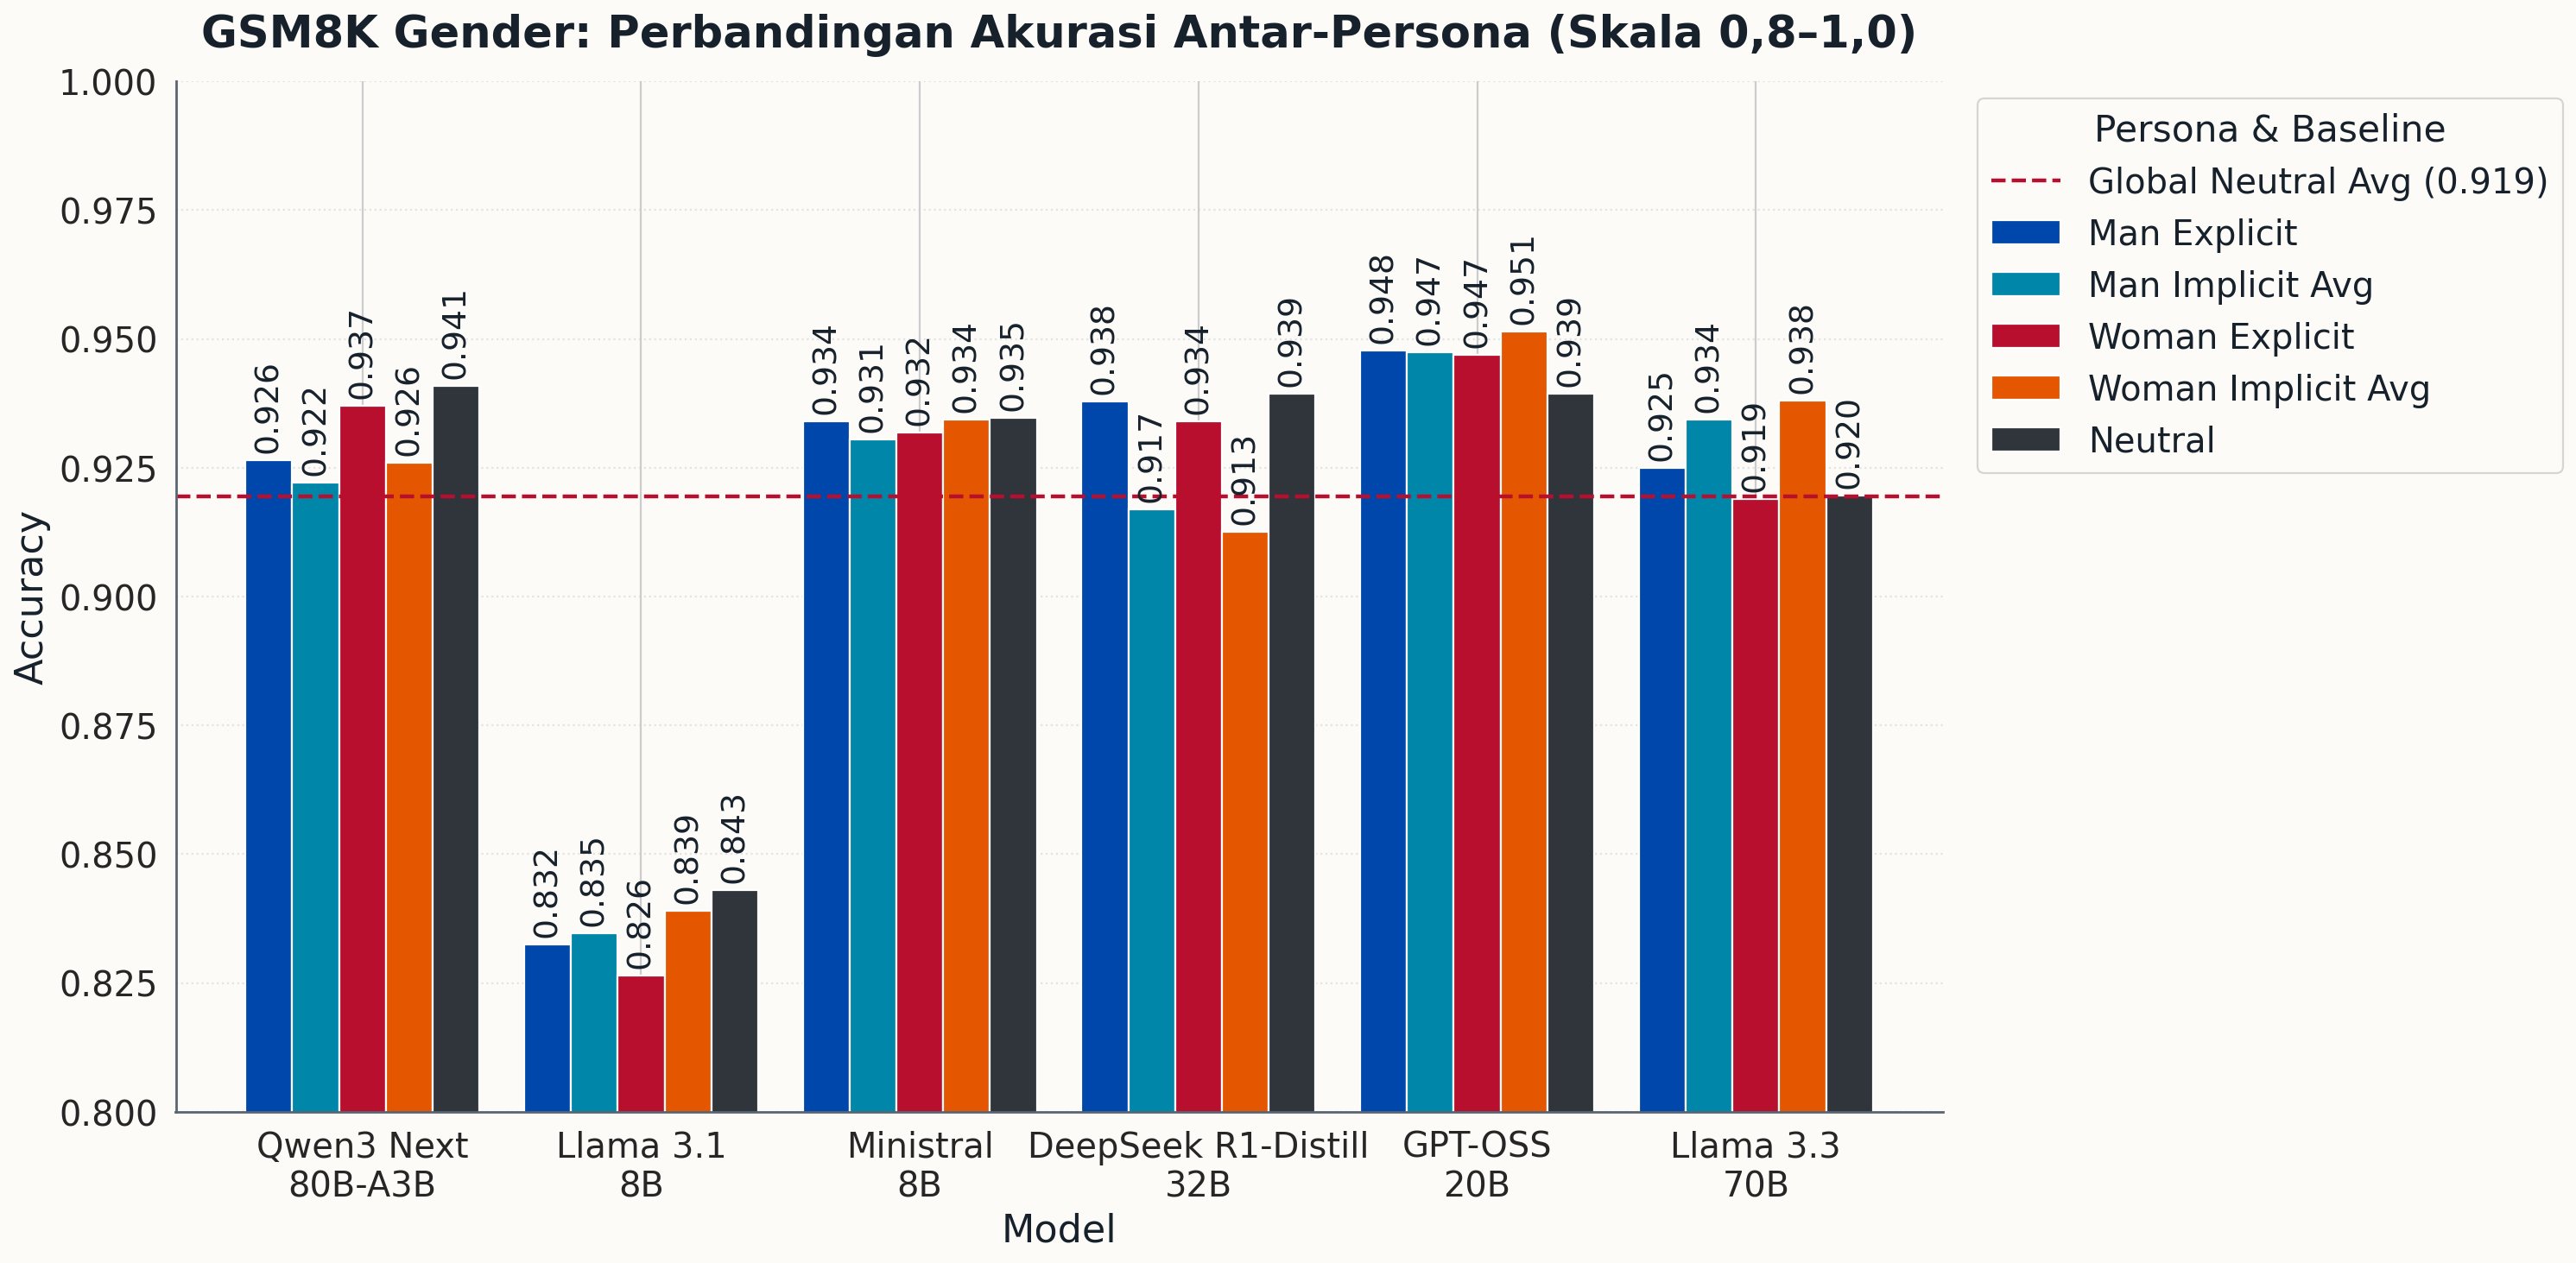

### `02_gender_delta_vs_neutral.png`

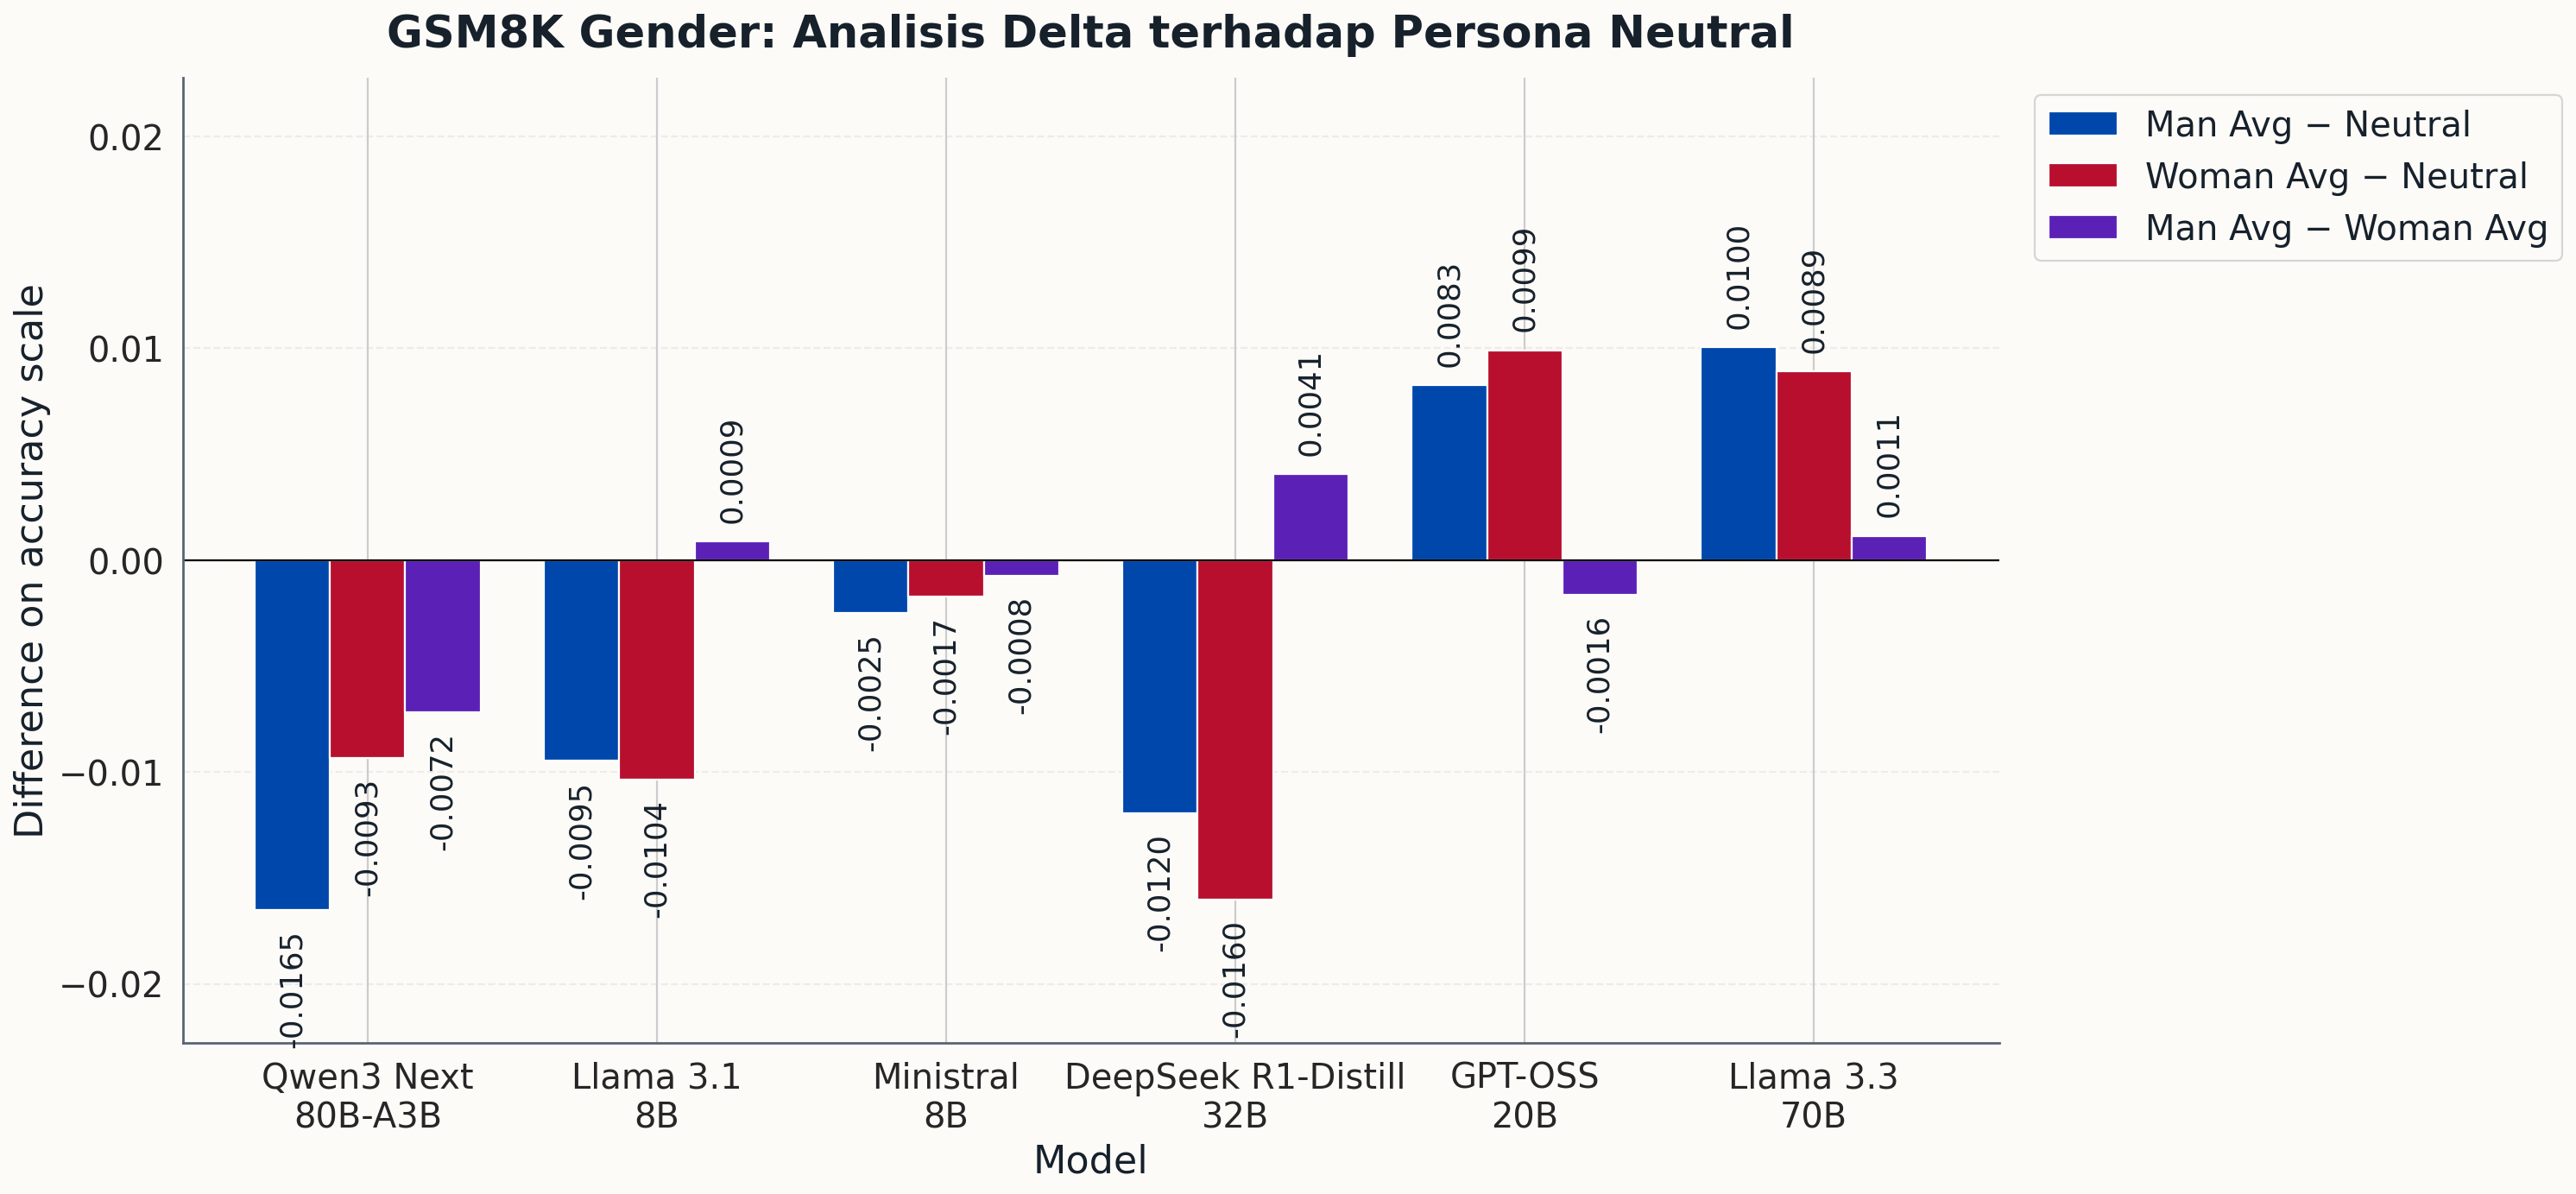

### `03_gender_delta_implicit_vs_explicit.png`

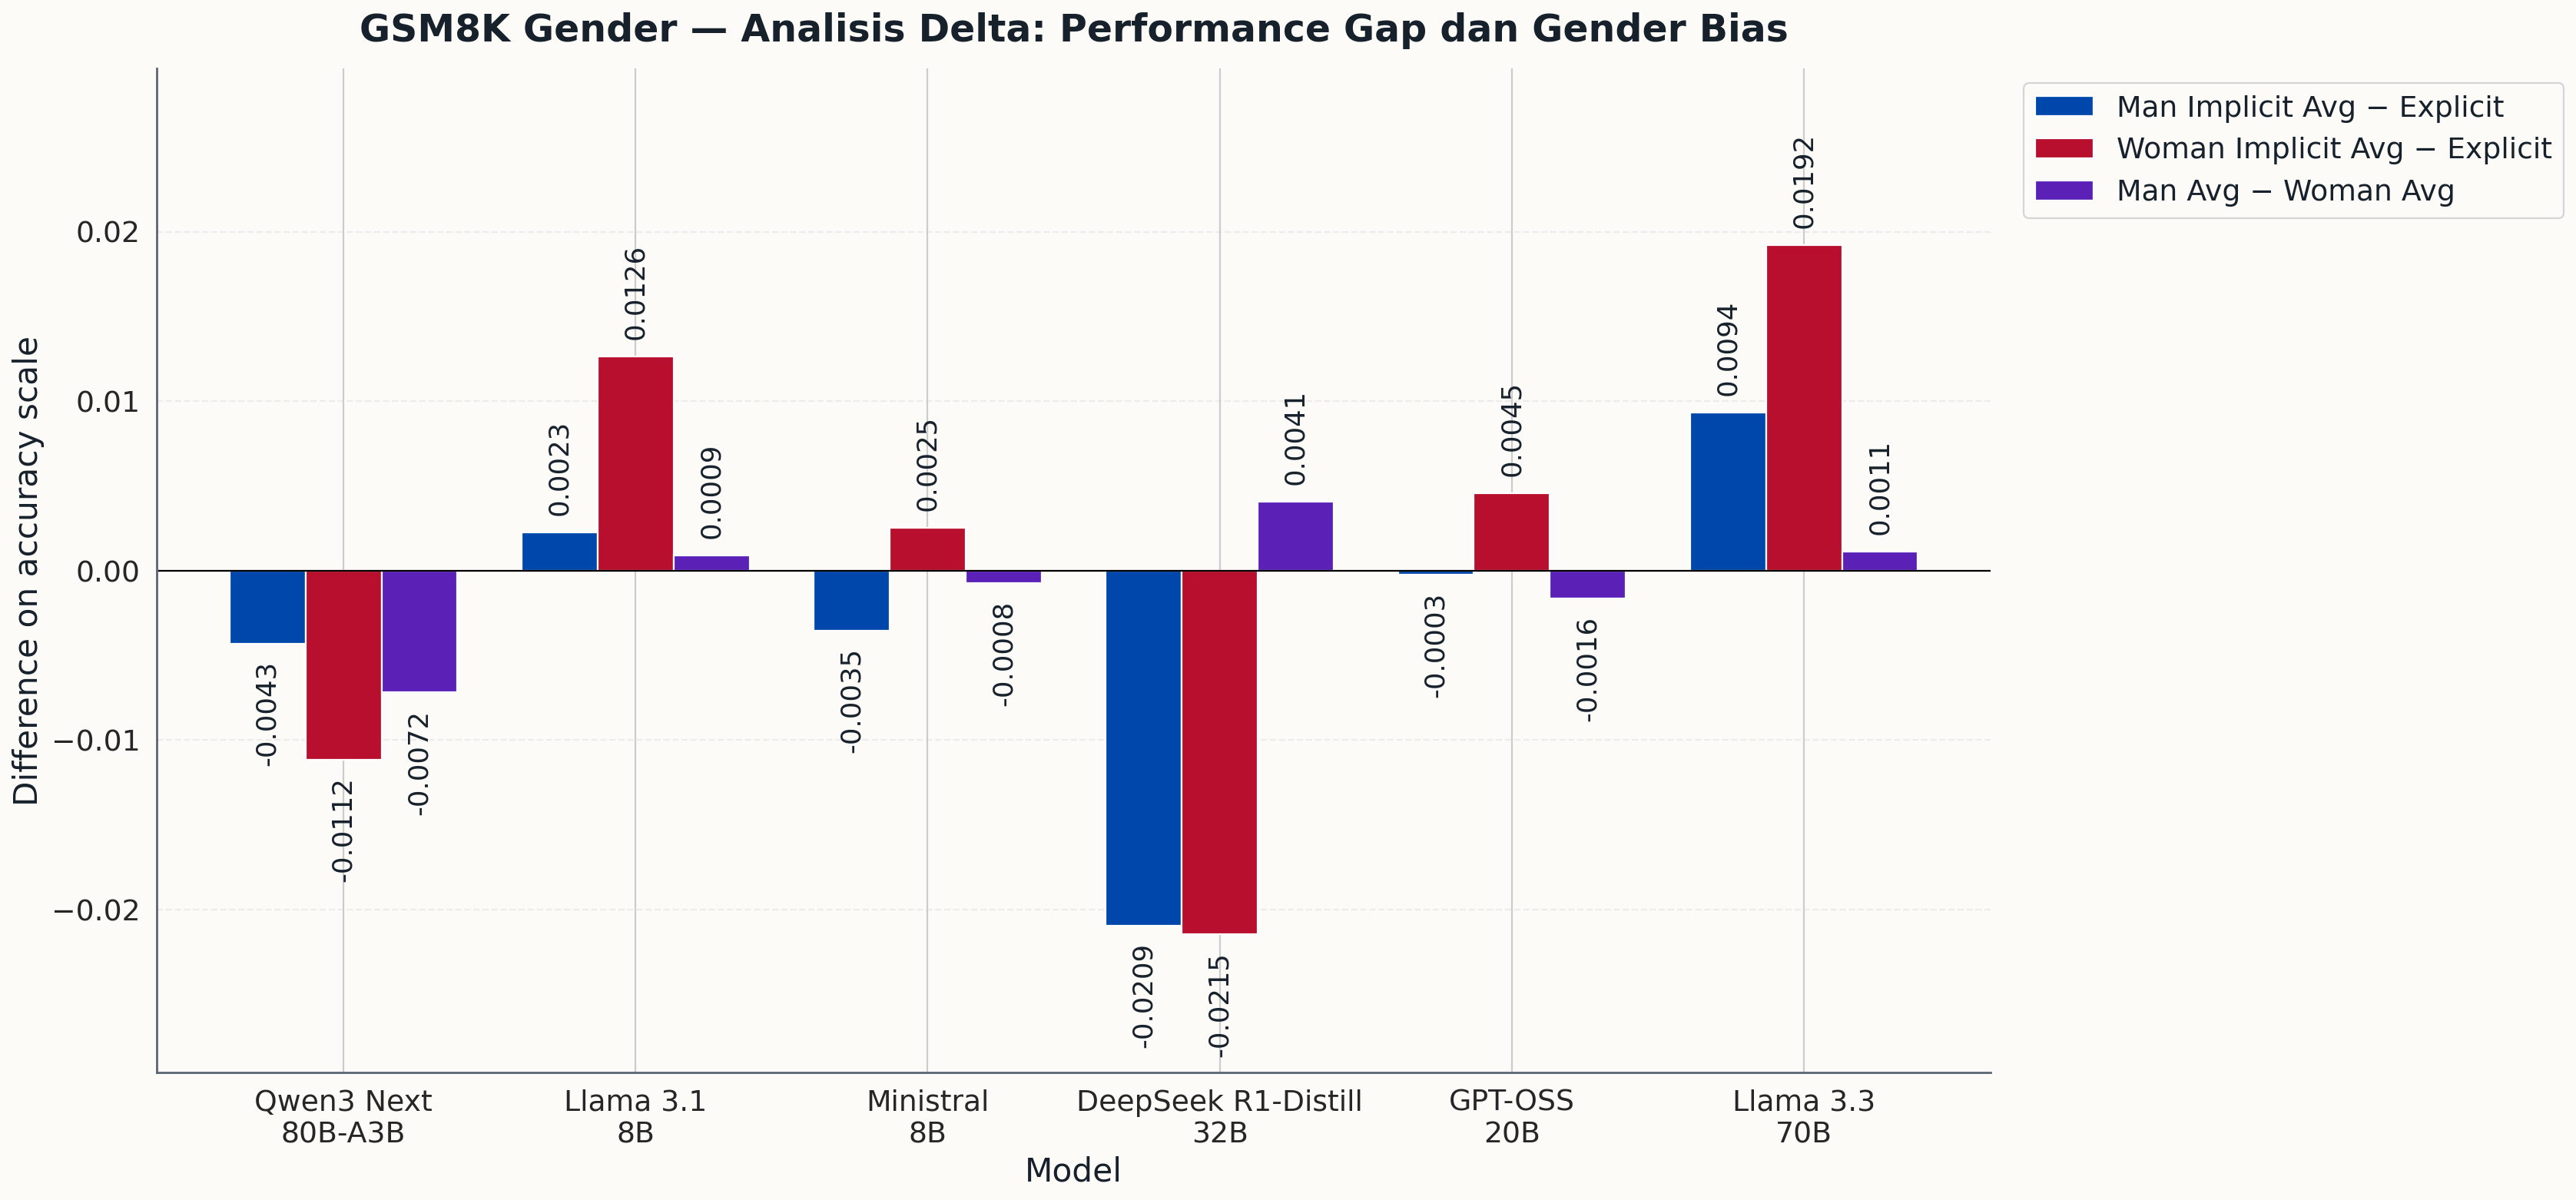

In [6]:
def show_figure(file_name: str, width: int = 1250) -> None:
    path = FIGURE_DIR / file_name
    if not path.is_file() or path.stat().st_size == 0:
        raise FileNotFoundError(path)
    display(Markdown(f"### `{file_name}`"))
    display(Image(filename=str(path), width=width))


show_figure("01_gender_absolute_accuracy_five_categories.png", width=1350)
show_figure("02_gender_delta_vs_neutral.png", width=1350)
show_figure("03_gender_delta_implicit_vs_explicit.png", width=1350)

## 6. Effect size, Exact McNemar, dan koreksi Holm

In [7]:
paired_columns = [
    "model_label", "identity", "family", "family_size", "comparison_label",
    "n_pairs", "accuracy_a_pct", "accuracy_b_pct", "risk_difference_pp",
    "risk_difference_ci95_low_pp", "risk_difference_ci95_high_pp", "cohen_h",
    "discordant_a_correct_only", "discordant_b_correct_only",
    "mcnemar_exact_p_value", "holm_adjusted_p_value",
    "omnibus_cochran_q_p_value", "significant_holm_0_05",
    "decision_significant_0_05", "supports_primary_claim",
]
gender_pairwise_table = gender_pairs[paired_columns].sort_values(
    ["model_label", "identity", "family", "comparison_label"]
).reset_index(drop=True)
display(gender_pairwise_table)

,model_label,identity,family,family_size,comparison_label,n_pairs,accuracy_a_pct,accuracy_b_pct,risk_difference_pp,risk_difference_ci95_low_pp,risk_difference_ci95_high_pp,cohen_h,discordant_a_correct_only,discordant_b_correct_only,mcnemar_exact_p_value,holm_adjusted_p_value,omnibus_cochran_q_p_value,significant_holm_0_05,decision_significant_0_05,supports_primary_claim
0,DeepSeek R1-Distill 32B,man,man_primary_seven,7,Man Explicit - Neutral,1318,93.7785,93.9302,-0.1517,-1.2898,0.9863,-0.0063,29,31,0.8974,0.8974,0.0002,False,False,False
1,DeepSeek R1-Distill 32B,man,man_primary_seven,7,Man Implicit 1 - Man Explicit,1319,90.8264,93.7832,-2.9568,-4.7005,-1.2889,-0.1114,47,86,0.0009,0.0055,0.0002,True,True,True
2,DeepSeek R1-Distill 32B,man,man_primary_seven,7,Man Implicit 1 - Neutral,1318,90.8953,93.9302,-3.0349,-4.6282,-1.4416,-0.1152,42,82,0.0004,0.0029,0.0002,True,True,True
3,DeepSeek R1-Distill 32B,man,man_primary_seven,7,Man Implicit 2 - Man Explicit,1319,91.6603,93.7832,-2.1228,-3.7149,-0.5307,-0.0819,46,74,0.0134,0.0535,0.0002,False,False,False
4,DeepSeek R1-Distill 32B,man,man_primary_seven,7,Man Implicit 2 - Neutral,1318,91.6540,93.9302,-2.2762,-3.8695,-0.6829,-0.0883,43,73,0.0068,0.0342,0.0002,True,True,True
5,DeepSeek R1-Distill 32B,man,man_primary_seven,7,Man Implicit 3 - Man Explicit,1319,92.5701,93.7832,-1.2130,-2.7293,0.3052,-0.0482,46,62,0.1486,0.2972,0.0002,False,False,False
6,DeepSeek R1-Distill 32B,man,man_primary_seven,7,Man Implicit 3 - Neutral,1318,92.5645,93.9302,-1.3657,-2.8073,0.0759,-0.0545,40,58,0.0854,0.2562,0.0002,False,False,False
7,DeepSeek R1-Distill 32B,man_vs_woman,gender_cross_identity_four,4,Man Explicit - Woman Explicit,1319,93.7832,93.4041,0.3791,-0.7582,1.5163,0.0155,32,27,0.6029,1.0000,NaN,False,False,False
8,DeepSeek R1-Distill 32B,man_vs_woman,gender_cross_identity_four,4,Man Implicit 1 - Woman Implicit 1,1319,90.8264,90.2199,0.6065,-1.1372,2.3503,0.0207,75,67,0.5571,1.0000,NaN,False,False,False
9,DeepSeek R1-Distill 32B,man_vs_woman,gender_cross_identity_four,4,Man Implicit 2 - Woman Implicit 2,1318,91.6540,91.0470,0.6070,-0.9863,2.2003,0.0216,62,54,0.5159,1.0000,NaN,False,False,False


### `04_gender_granular_effect_size_heatmap.png`

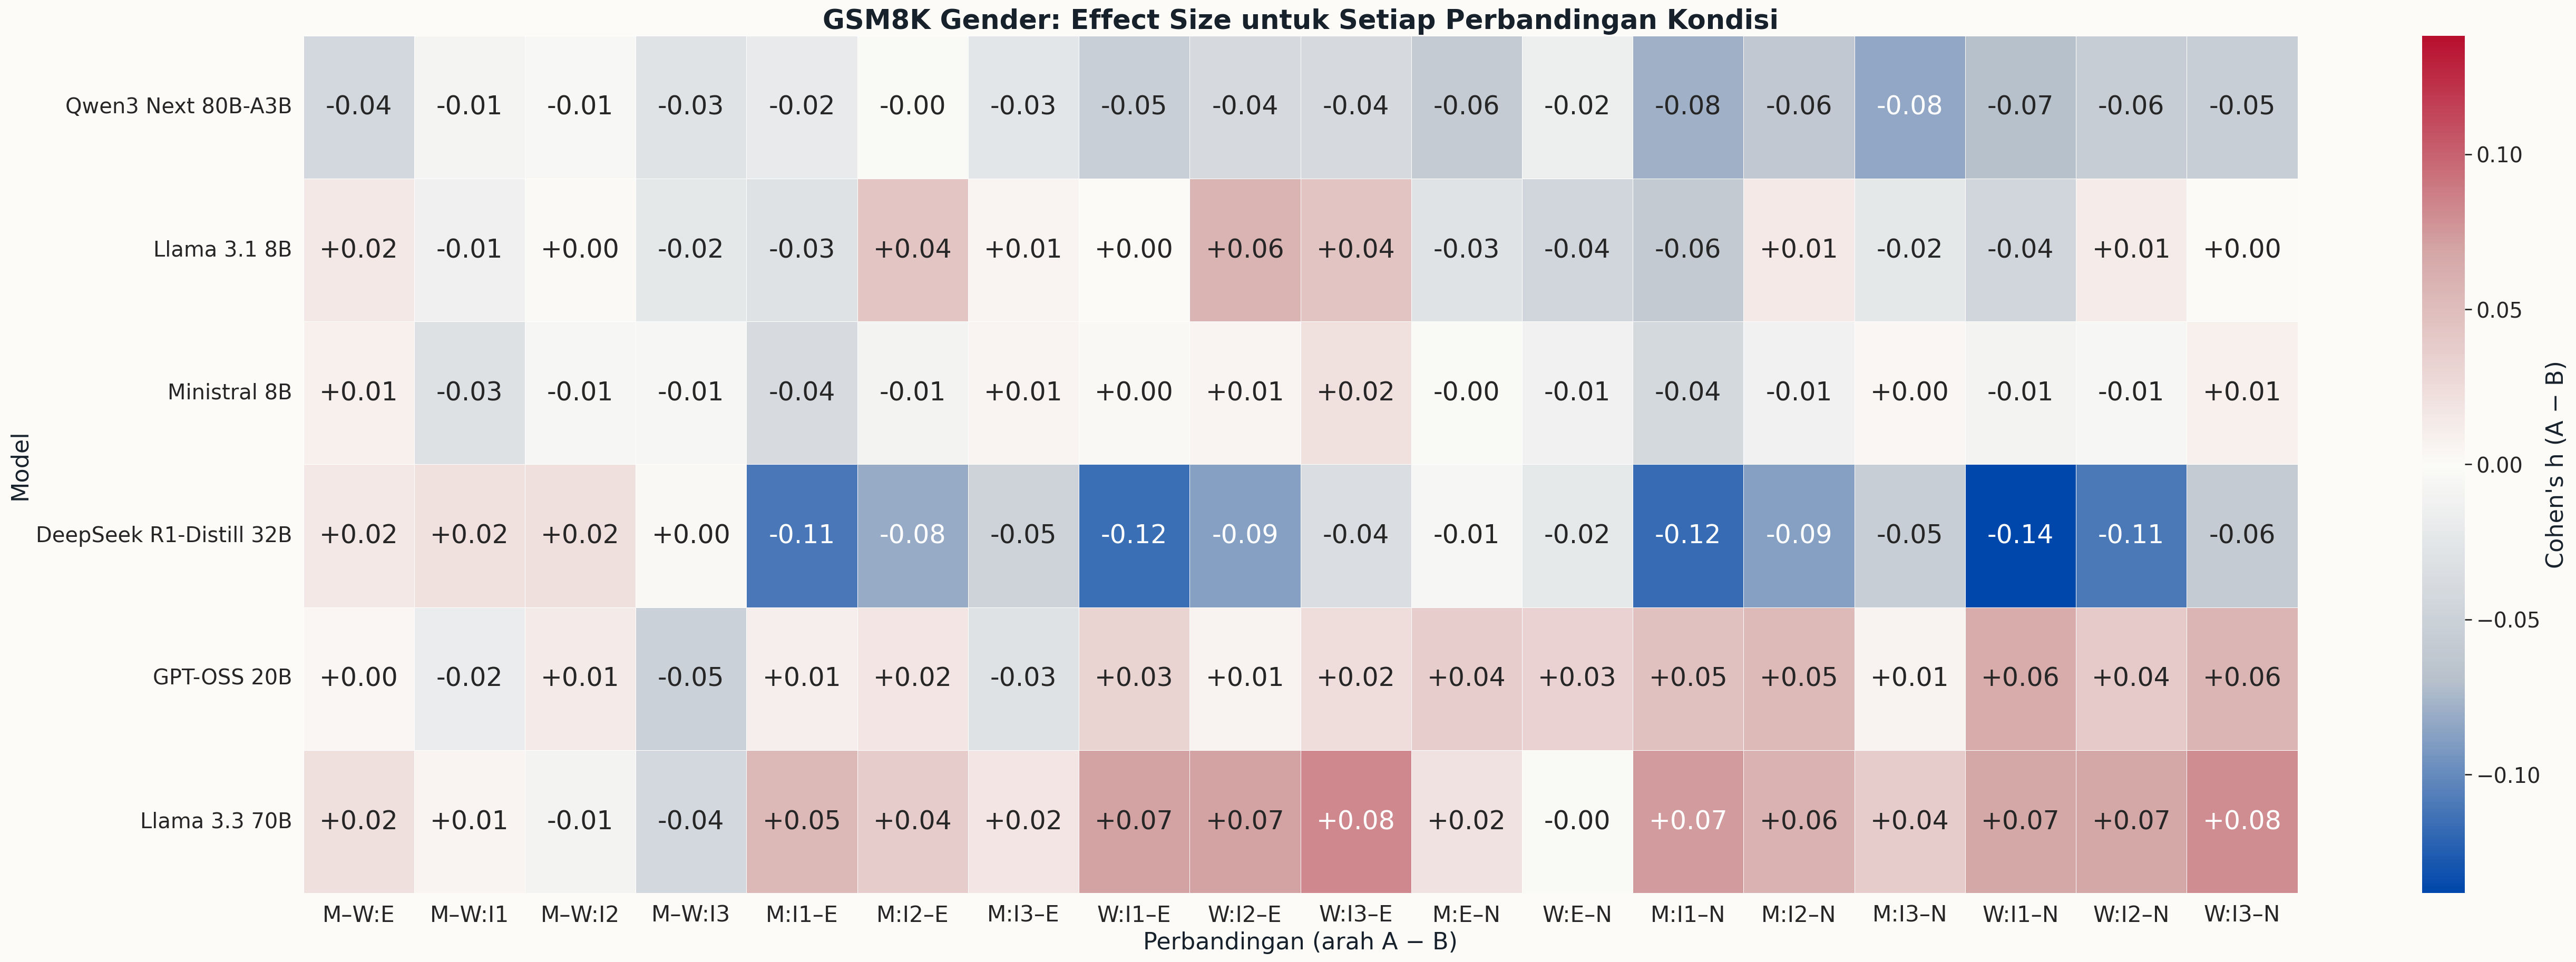

### `17_gender_exact_mcnemar_and_holm_pvalue_heatmap.png`

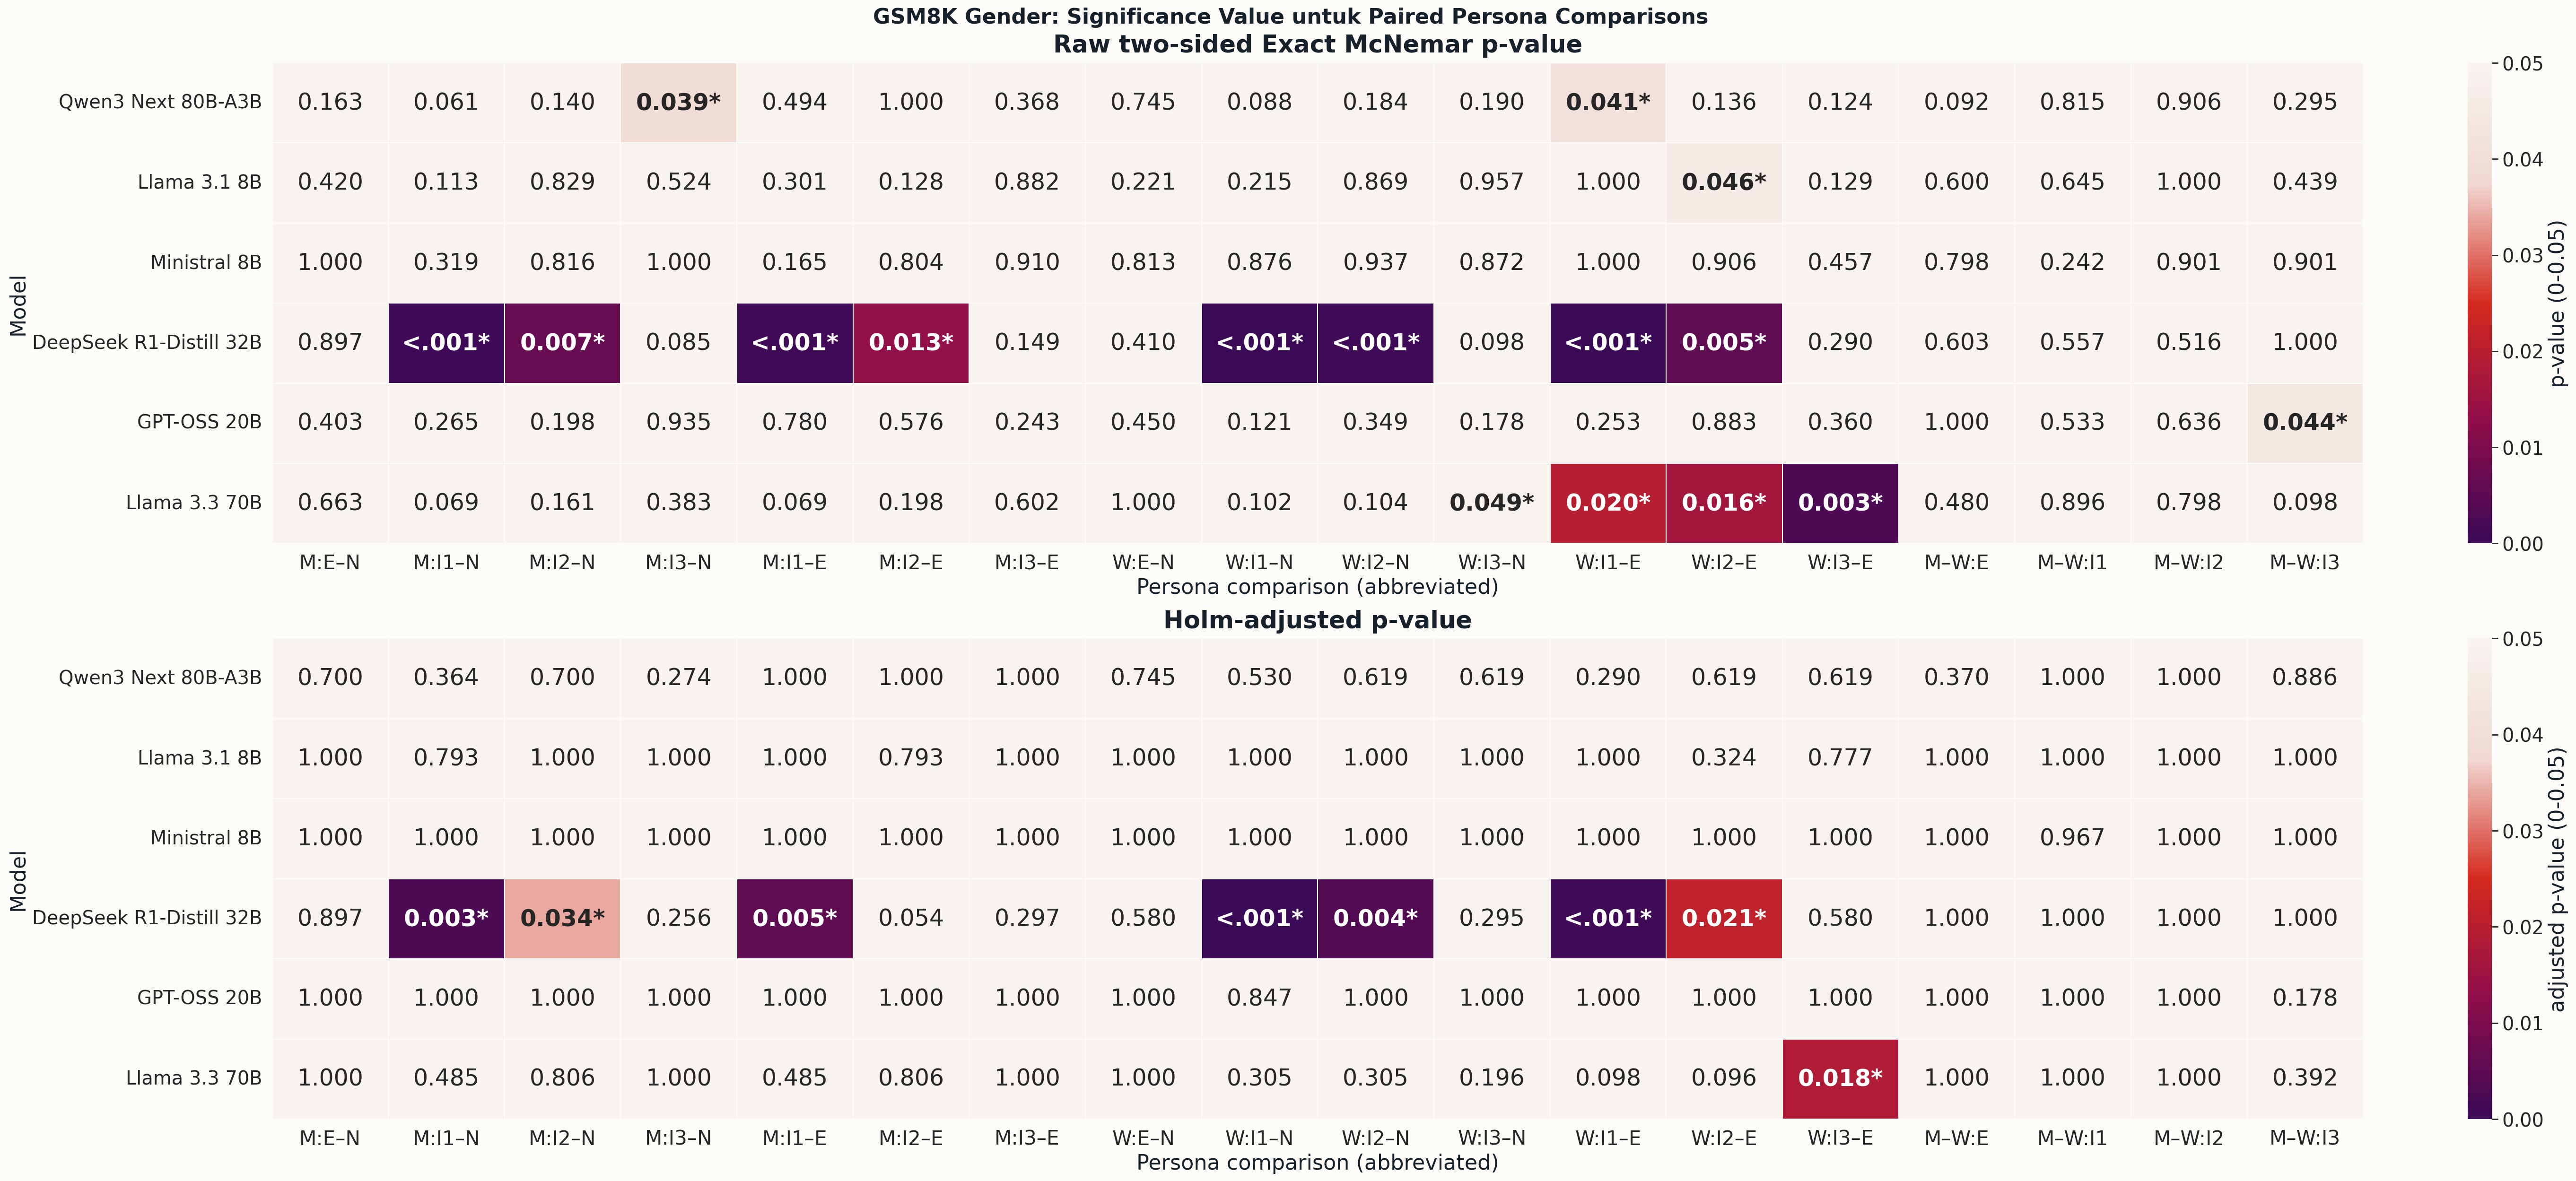

In [8]:
show_figure("04_gender_granular_effect_size_heatmap.png", width=1400)
show_figure("17_gender_exact_mcnemar_and_holm_pvalue_heatmap.png", width=1500)

### Heatmap tunggal ukuran efek + keputusan Holm

Visual berikut adalah bentuk final yang dirujuk Bab VI. Sel berisi Cohen's h;
`*` dan cetak tebal hanya digunakan jika `significant_holm_0_05 = true`.
Skala Cohen's h ditahan pada −0,15 sampai +0,15 agar perbandingan antarmodel konsisten.

### `24_gender_effect_holm_single_large_heatmap.png`

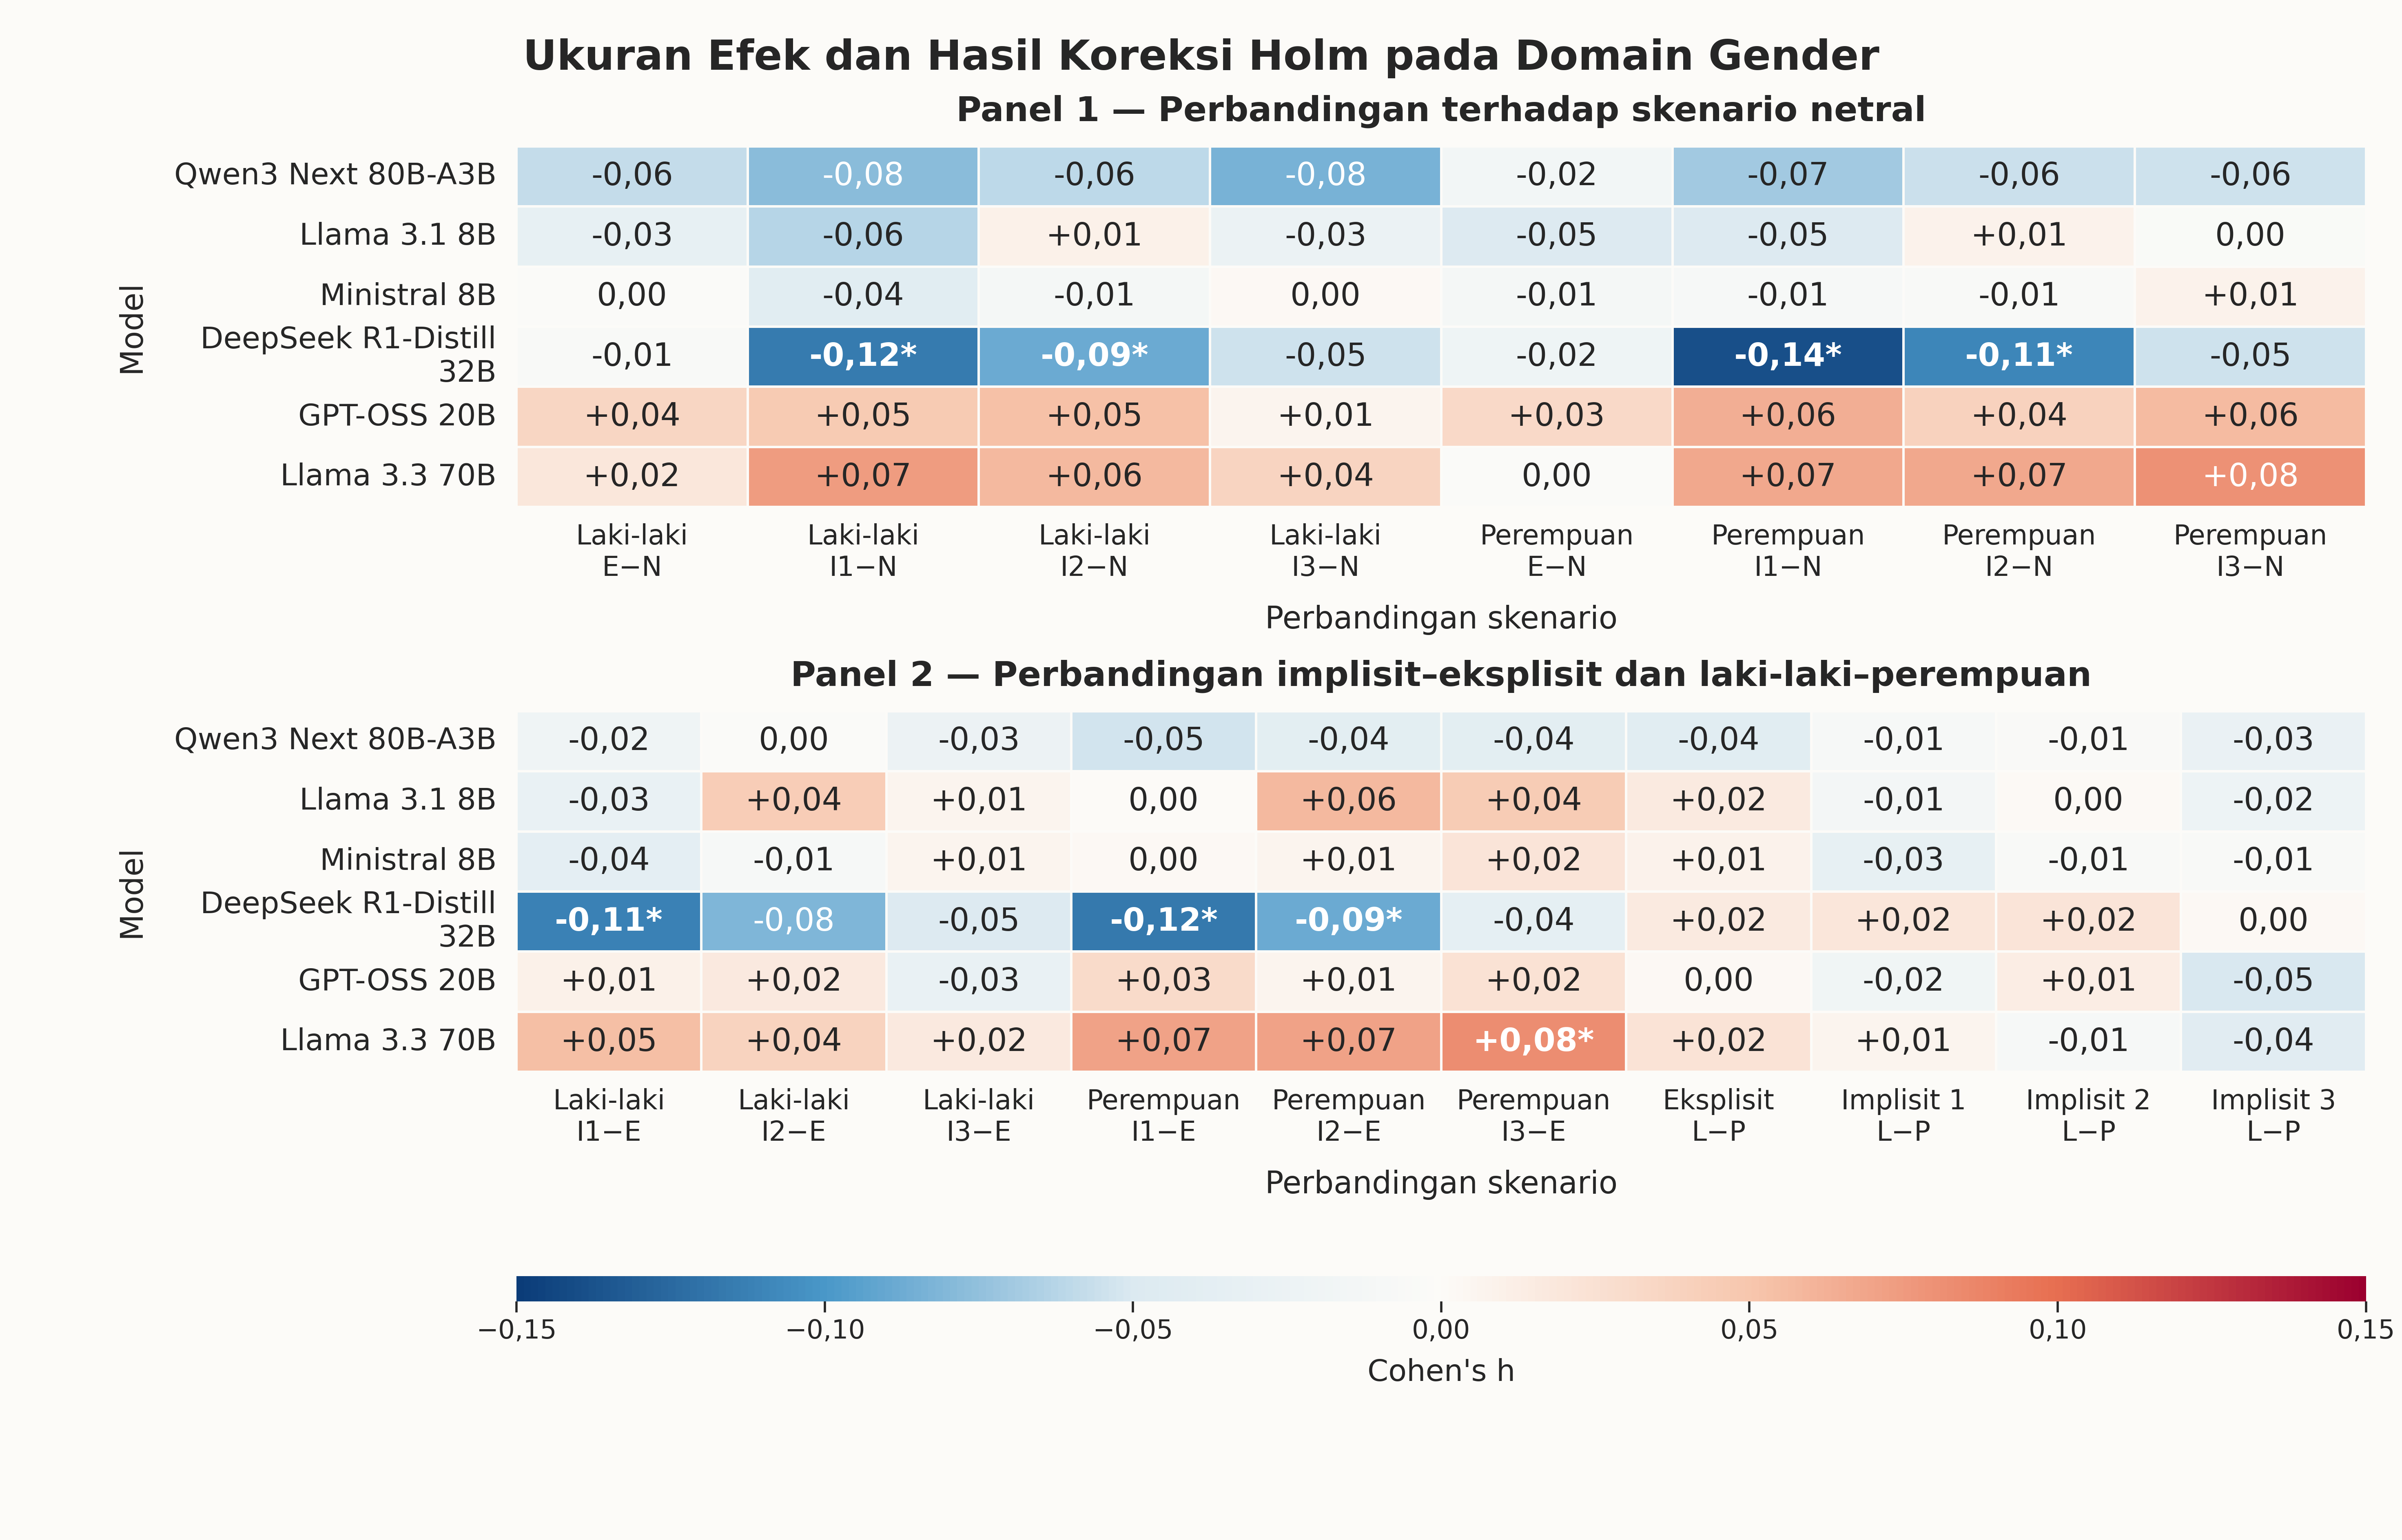

In [9]:
show_figure("24_gender_effect_holm_single_large_heatmap.png", width=1550)

## 7. Tabel dan visual token Gender

In [10]:
token_categories_all = pd.read_csv(TABLE_DIR / "token_category_summary_six_models.csv")
gender_token_categories = token_categories_all[token_categories_all["dataset"].eq("Gender")].copy()
token_delta = pd.read_csv(TABLE_DIR / "gender_completion_token_delta_vs_neutral_pct.csv")
token_tradeoff = pd.read_csv(
    TABLE_DIR / "gender_completion_token_accuracy_tradeoff_implicit_vs_explicit.csv"
)
token_spearman = pd.read_csv(
    TABLE_DIR / "gender_completion_token_accuracy_spearman_exploratory.csv"
)

display(Markdown("### Ringkasan token per kategori"))
display(gender_token_categories)
display(Markdown("### Delta completion token terhadap Neutral"))
display(token_delta)
display(Markdown("### Completion token–accuracy trade-off"))
display(token_tradeoff)
display(Markdown("### Spearman exploratory/descriptive"))
display(token_spearman)

### Ringkasan token per kategori

,dataset,model,model_label,category,avg_completion_tokens,avg_reasoning_tokens
0,Gender,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Neutral,945.2800,NaN
1,Gender,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Man Explicit,910.7415,NaN
2,Gender,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Man Implicit Avg,"1,001.7465",NaN
3,Gender,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Woman Explicit,912.2130,NaN
4,Gender,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,Woman Implicit Avg,"1,006.4785",NaN
5,Gender,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,Neutral,185.4320,NaN
6,Gender,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,Man Explicit,187.7551,NaN
7,Gender,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,Man Implicit Avg,197.0740,NaN
8,Gender,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,Woman Explicit,193.5292,NaN
9,Gender,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,Woman Implicit Avg,189.9278,NaN


### Delta completion token terhadap Neutral

,model_label,M:E,M:I Avg,W:E,W:I Avg
0,Qwen3 Next 80B-A3B,-3.6538,5.9735,-3.4981,6.4741
1,Llama 3.1 8B,1.2528,6.2783,4.3666,2.4245
2,Ministral 8B,-3.5758,-4.4212,-2.6355,-4.3927
3,DeepSeek R1-Distill 32B,-1.4688,80.0996,1.0761,81.9706
4,GPT-OSS 20B,-13.0536,-19.4683,-14.8580,-18.8950
5,Llama 3.3 70B,2.5389,6.9259,0.9068,4.2010


### Completion token–accuracy trade-off

,model,model_label,identity,implicit_persona,variant,implicit_accuracy_pct,implicit_avg_completion_tokens,explicit_persona,explicit_accuracy_pct,explicit_avg_completion_tokens,identity_label,implicit_variant,token_delta_pct,accuracy_delta_pp,analysis_scope,token_metric
0,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,man,man_implicit_1,1,90.8300,825.3361,man_explicit_1,93.7800,429.6843,Man,Implicit 1,92.0797,-2.9500,exploratory_descriptive,avg_completion_tokens
1,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,man,man_implicit_2,2,91.6600,774.6228,man_explicit_1,93.7800,429.6843,Man,Implicit 2,80.2772,-2.1200,exploratory_descriptive,avg_completion_tokens
2,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,man,man_implicit_3,3,92.5700,756.2274,man_explicit_1,93.7800,429.6843,Man,Implicit 3,75.9961,-1.2100,exploratory_descriptive,avg_completion_tokens
3,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,woman,woman_implicit_1,1,90.2200,840.7633,woman_explicit_1,93.4000,440.7825,Woman,Implicit 1,90.7433,-3.1800,exploratory_descriptive,avg_completion_tokens
4,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,woman,woman_implicit_2,2,91.0500,780.9664,woman_explicit_1,93.4000,440.7825,Woman,Implicit 2,77.1773,-2.3500,exploratory_descriptive,avg_completion_tokens
5,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,woman,woman_implicit_3,3,92.4900,758.9350,woman_explicit_1,93.4000,440.7825,Woman,Implicit 3,72.1790,-0.9100,exploratory_descriptive,avg_completion_tokens
6,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,man,man_implicit_1,1,82.1077,200.5610,man_explicit_1,83.2449,187.7551,Man,Implicit 1,6.8205,-1.1372,exploratory_descriptive,avg_completion_tokens
7,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,man,man_implicit_2,2,84.8370,184.0076,man_explicit_1,83.2449,187.7551,Man,Implicit 2,-1.9960,1.5921,exploratory_descriptive,avg_completion_tokens
8,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,man,man_implicit_3,3,83.4723,206.6535,man_explicit_1,83.2449,187.7551,Man,Implicit 3,10.0655,0.2274,exploratory_descriptive,avg_completion_tokens
9,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,woman,woman_implicit_1,1,82.6384,195.8620,woman_explicit_1,82.6384,193.5292,Woman,Implicit 1,1.2054,0.0000,exploratory_descriptive,avg_completion_tokens


### Spearman exploratory/descriptive

,scope,model,model_label,n_points,spearman_rho,raw_p_value_exploratory,analysis_scope,token_metric
0,per_model,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,6,-0.0286,0.9572,exploratory_descriptive,avg_completion_tokens
1,per_model,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,6,-0.7714,0.0724,exploratory_descriptive,avg_completion_tokens
2,per_model,mistralai_ministral-8b-2512,Ministral 8B,6,-0.1429,0.7872,exploratory_descriptive,avg_completion_tokens
3,per_model,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,6,-0.8857,0.0188,exploratory_descriptive,avg_completion_tokens
4,per_model,openai_gpt-oss-20b,GPT-OSS 20B,6,0.6000,0.2080,exploratory_descriptive,avg_completion_tokens
5,per_model,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,6,-0.2609,0.6175,exploratory_descriptive,avg_completion_tokens
6,delta_pooled_across_models,all_six_models,All six models,36,-0.6168,0.0001,exploratory_descriptive,avg_completion_tokens


### `08_gender_completion_tokens_by_category.png`

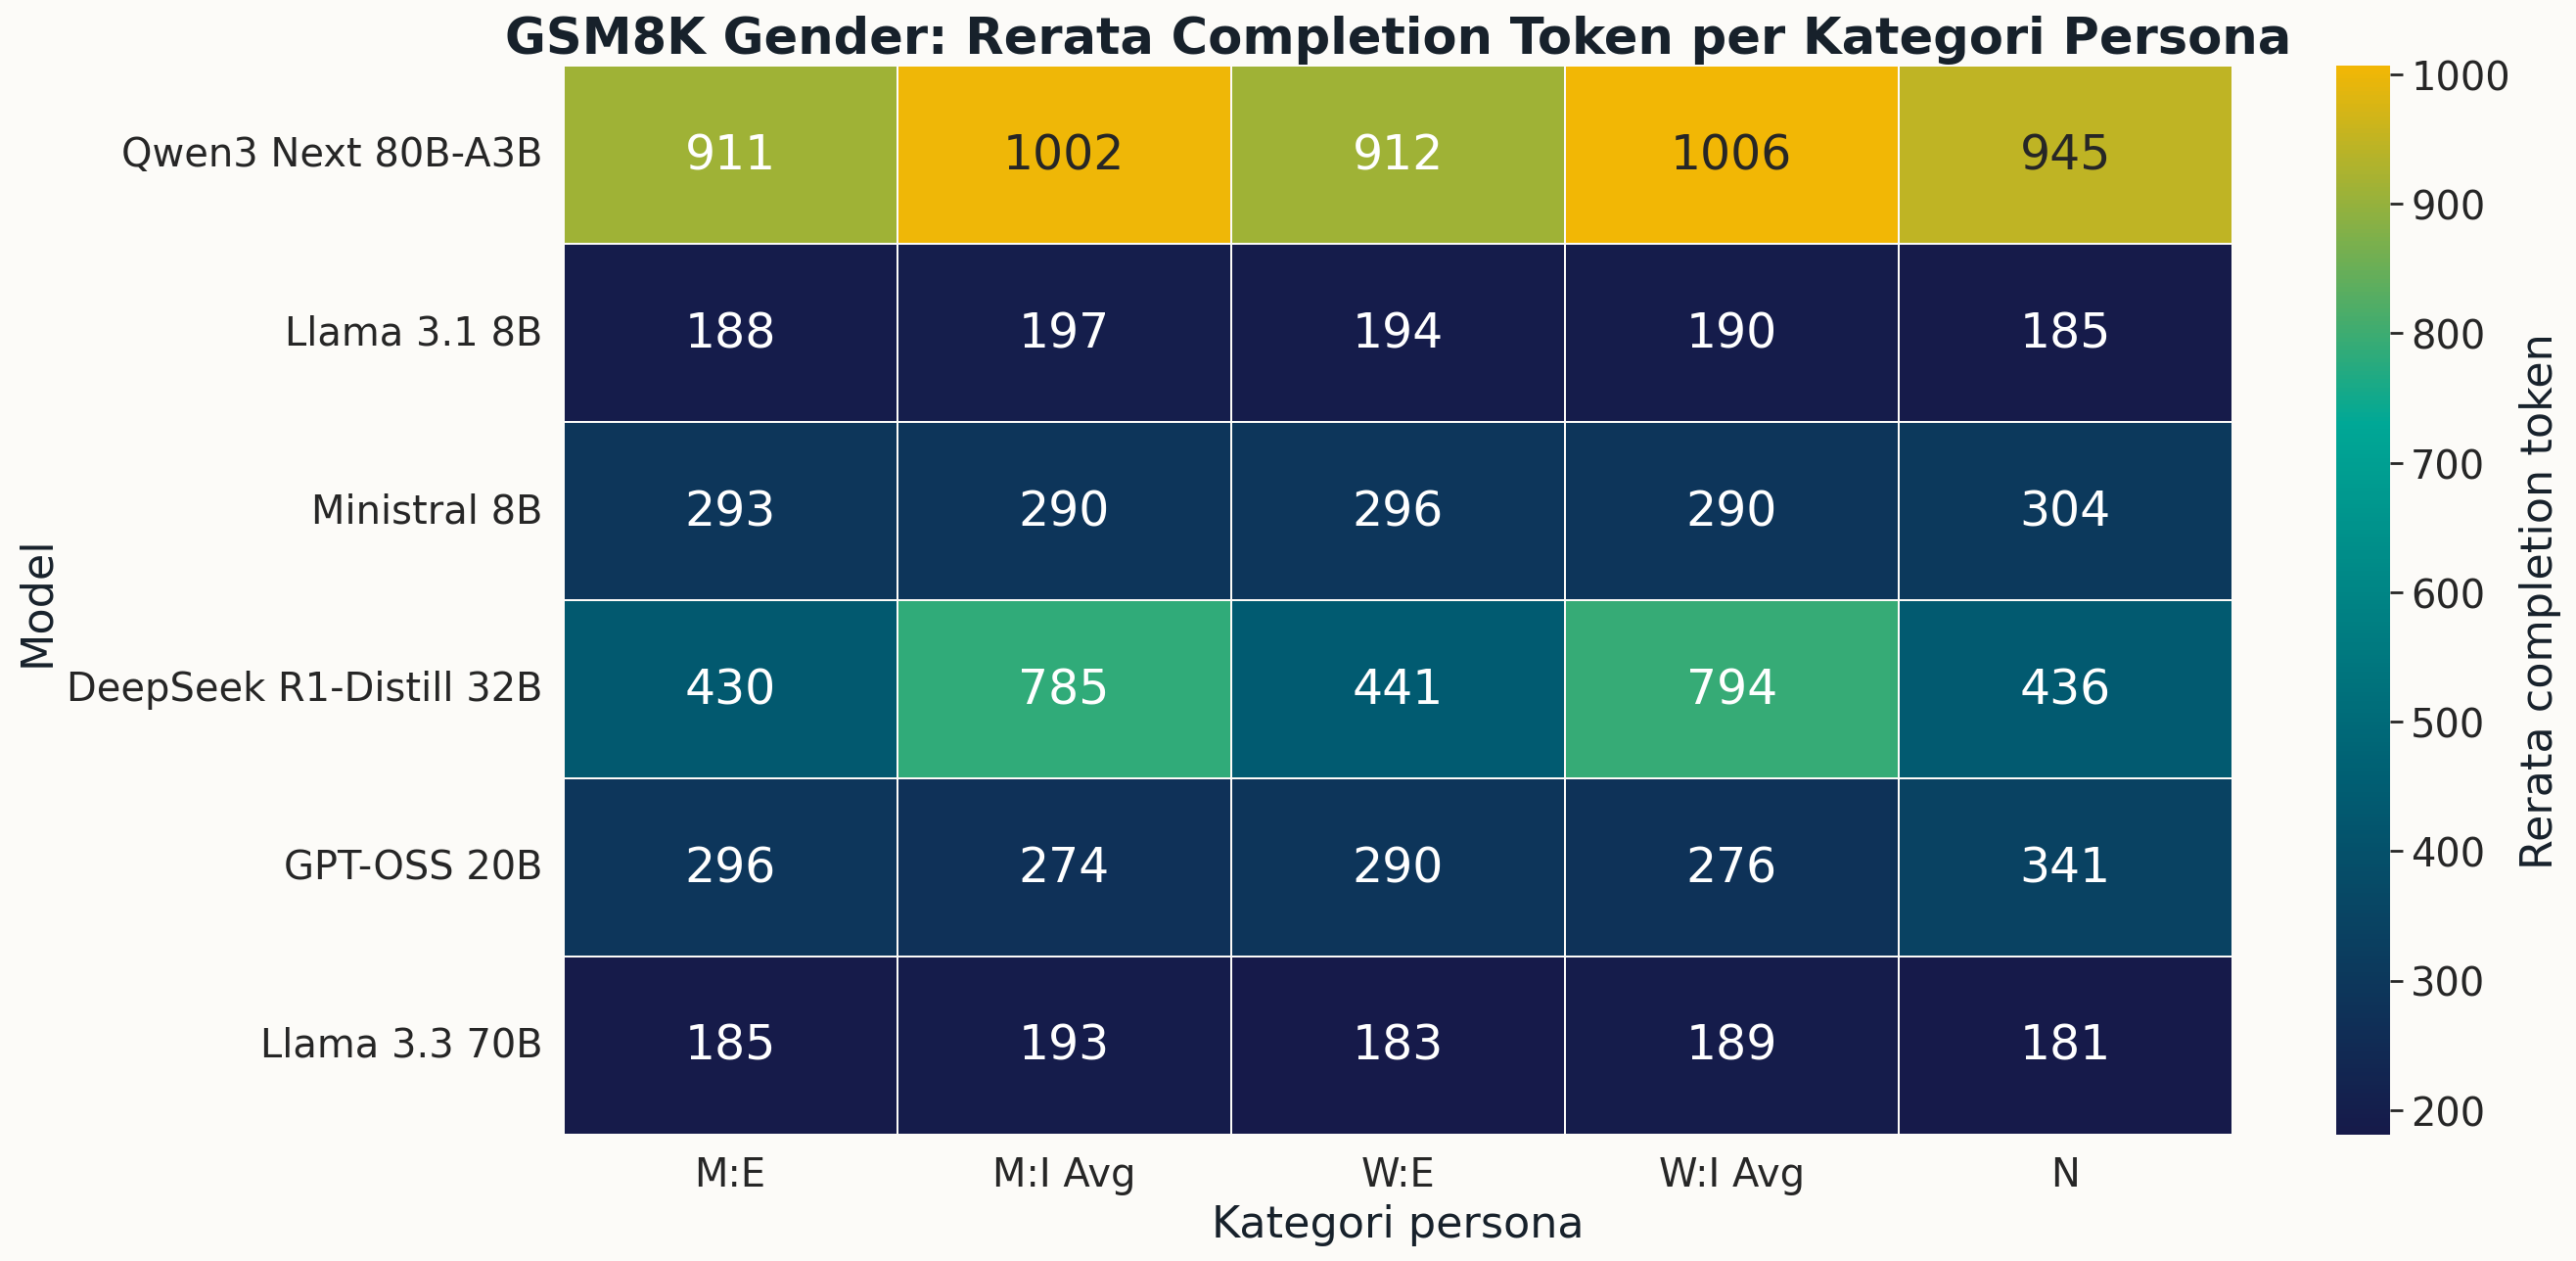

### `09_gender_completion_token_delta_vs_neutral.png`

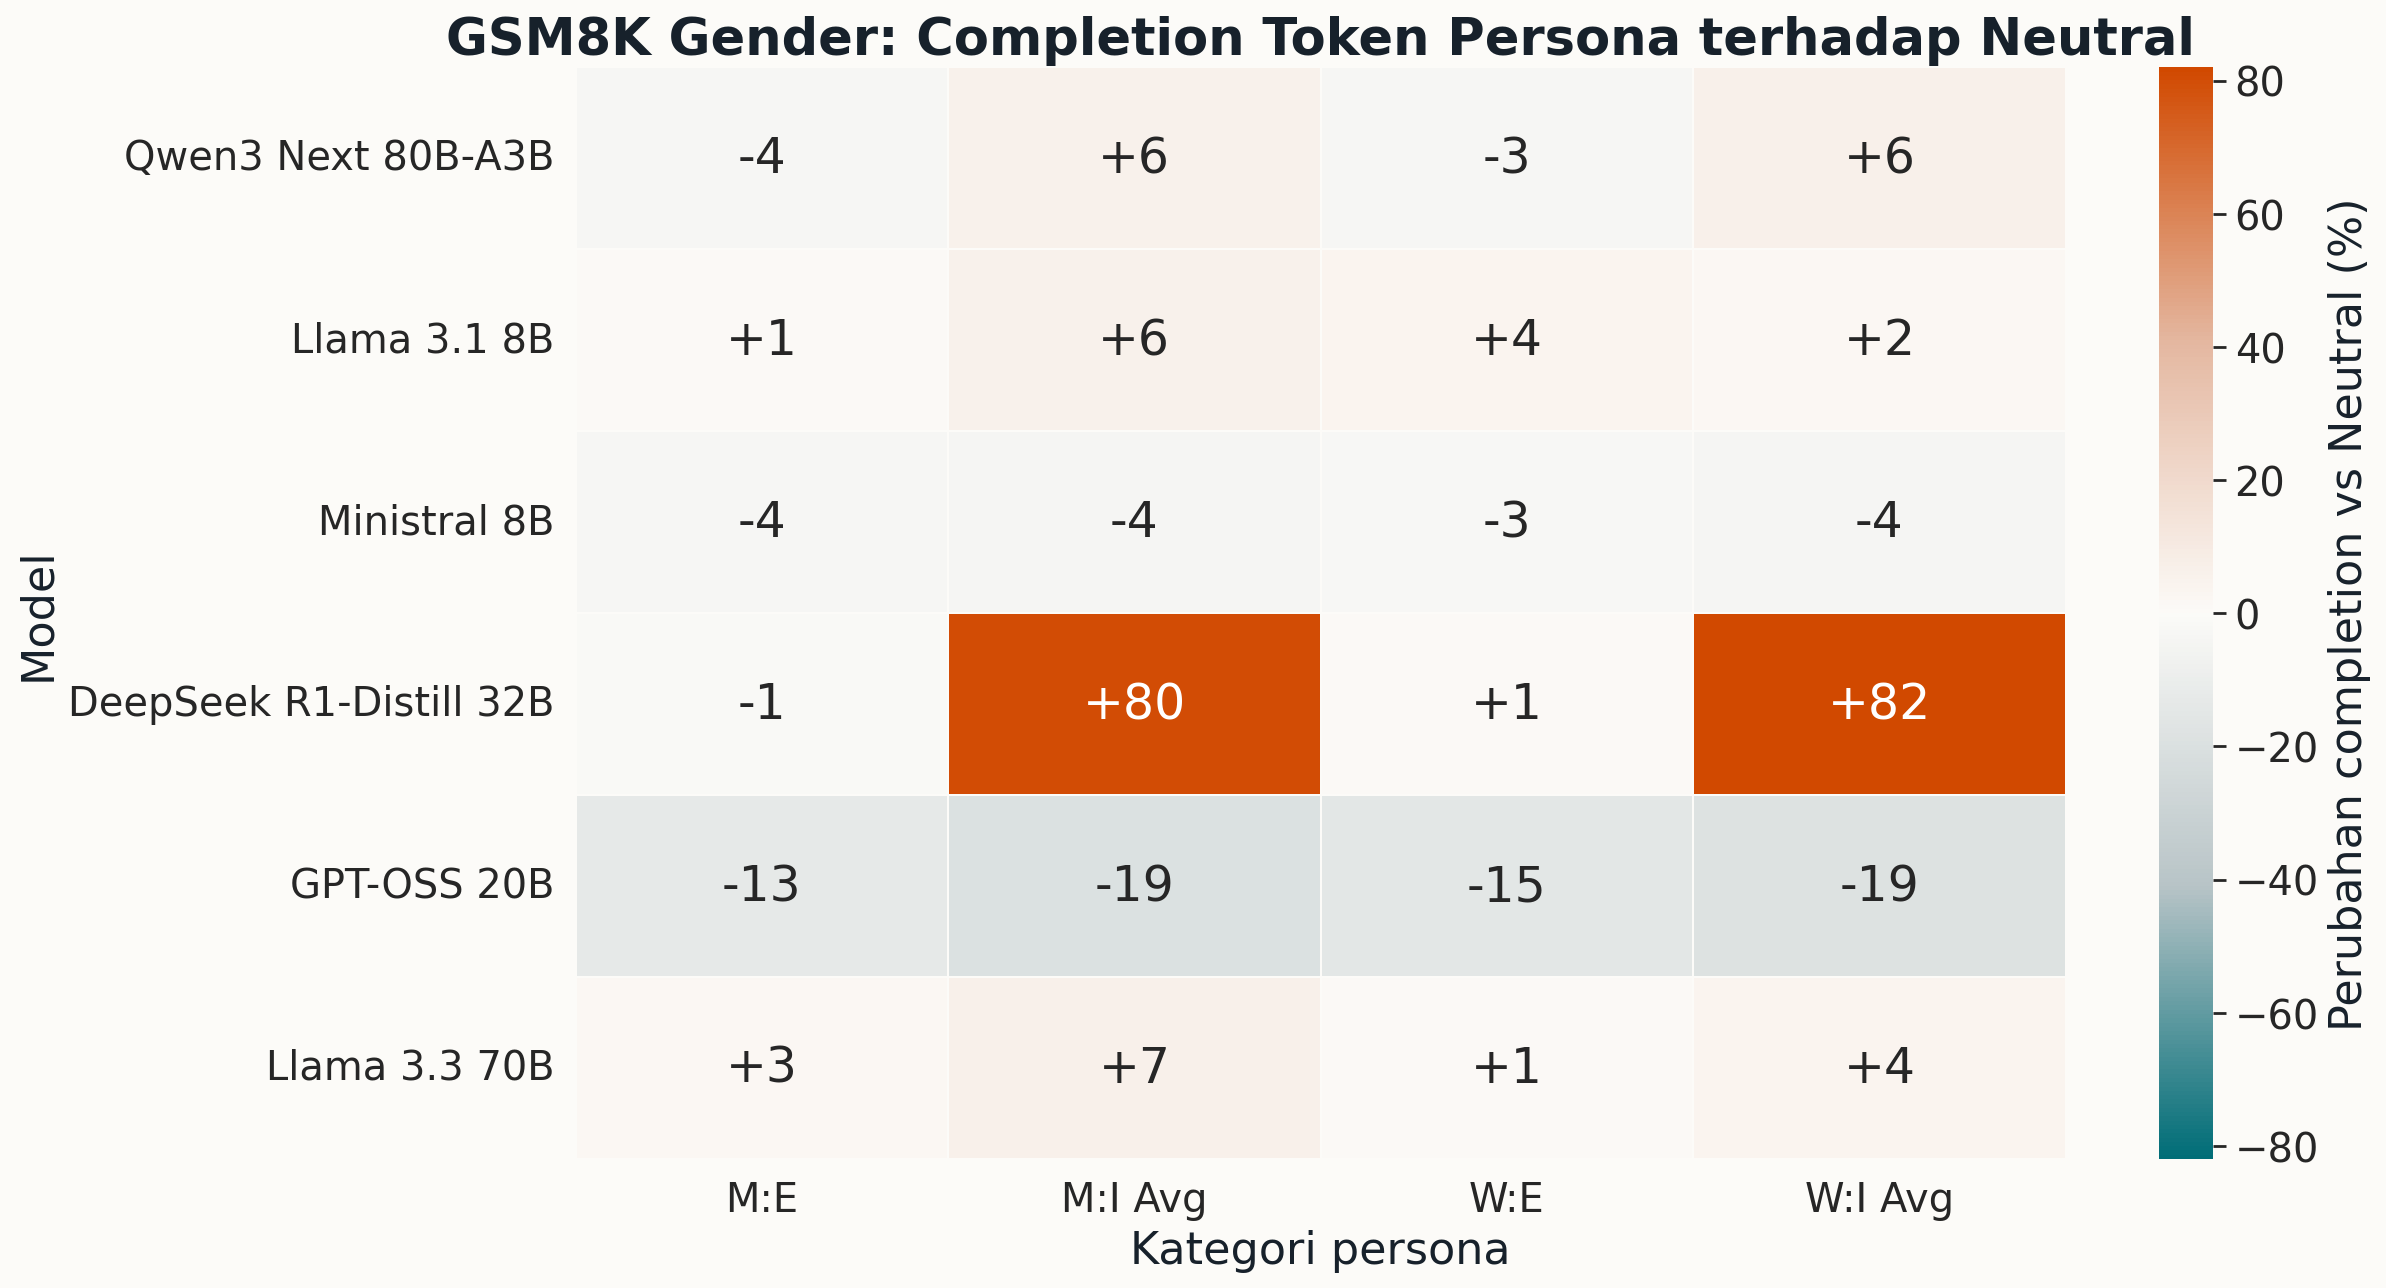

### `22_gender_completion_token_accuracy_tradeoff_implicit_vs_explicit.png`

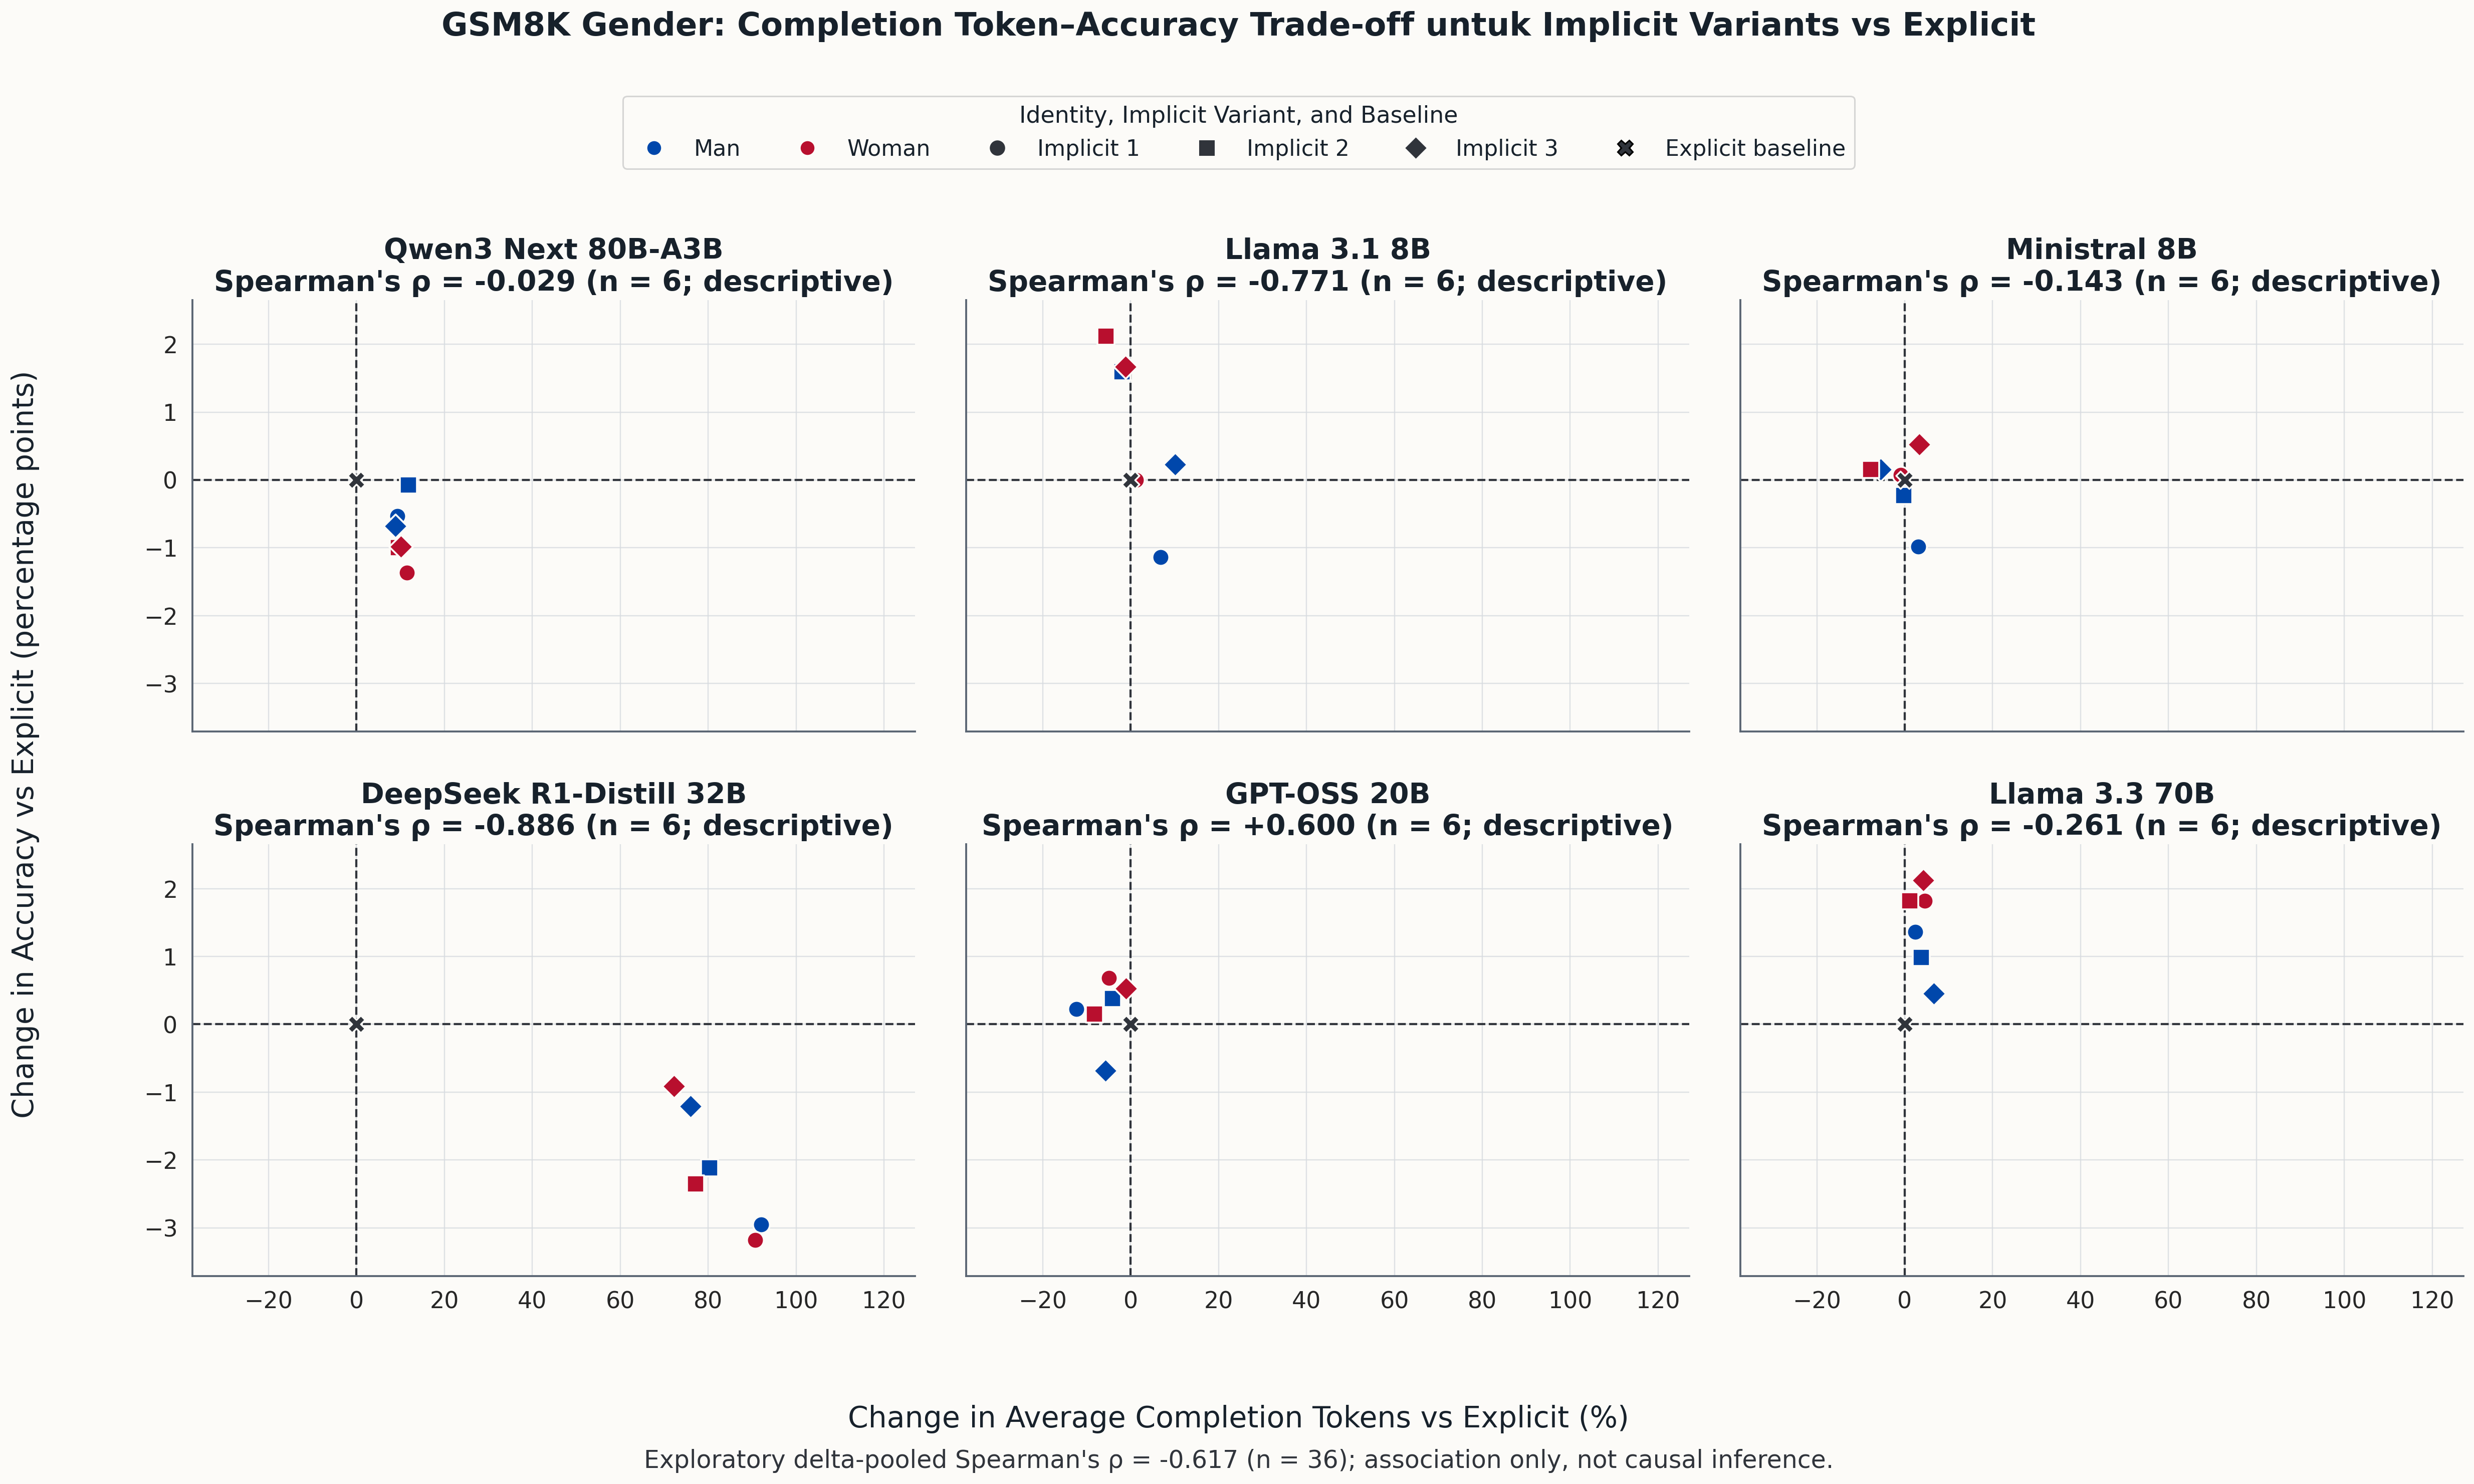

In [11]:
show_figure("08_gender_completion_tokens_by_category.png", width=1350)
show_figure("09_gender_completion_token_delta_vs_neutral.png", width=1350)
show_figure("22_gender_completion_token_accuracy_tradeoff_implicit_vs_explicit.png", width=1400)

## 8. Neutral baseline dan audit tambahan

### Neutral Persona

,model,model_label,persona,correct,total,accuracy_pct,accuracy_source_pct,question_level_accuracy_pct,accuracy_source
0,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,neutral,1240,1318,94.0819,94.0819,94.0819,akurasi gender&neutral persona.csv
1,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,neutral,1112,1317,84.3063,84.3063,84.4343,akurasi gender&neutral persona.csv
2,mistralai_ministral-8b-2512,Ministral 8B,neutral,1232,1318,93.4750,93.4750,93.4750,akurasi gender&neutral persona.csv
3,deepseek_deepseek-r1-distill-qwen-32b,DeepSeek R1-Distill 32B,neutral,1238,1318,93.9300,93.9300,93.9302,akurasi gender&neutral persona.csv
4,openai_gpt-oss-20b,GPT-OSS 20B,neutral,1238,1318,93.9302,93.9302,93.9302,akurasi gender&neutral persona.csv
5,meta-llama_llama-3.3-70b-instruct,Llama 3.3 70B,neutral,1212,1318,91.9575,91.9575,91.9575,akurasi gender&neutral persona.csv


### `23_neutral_persona_accuracy_six_models.png`

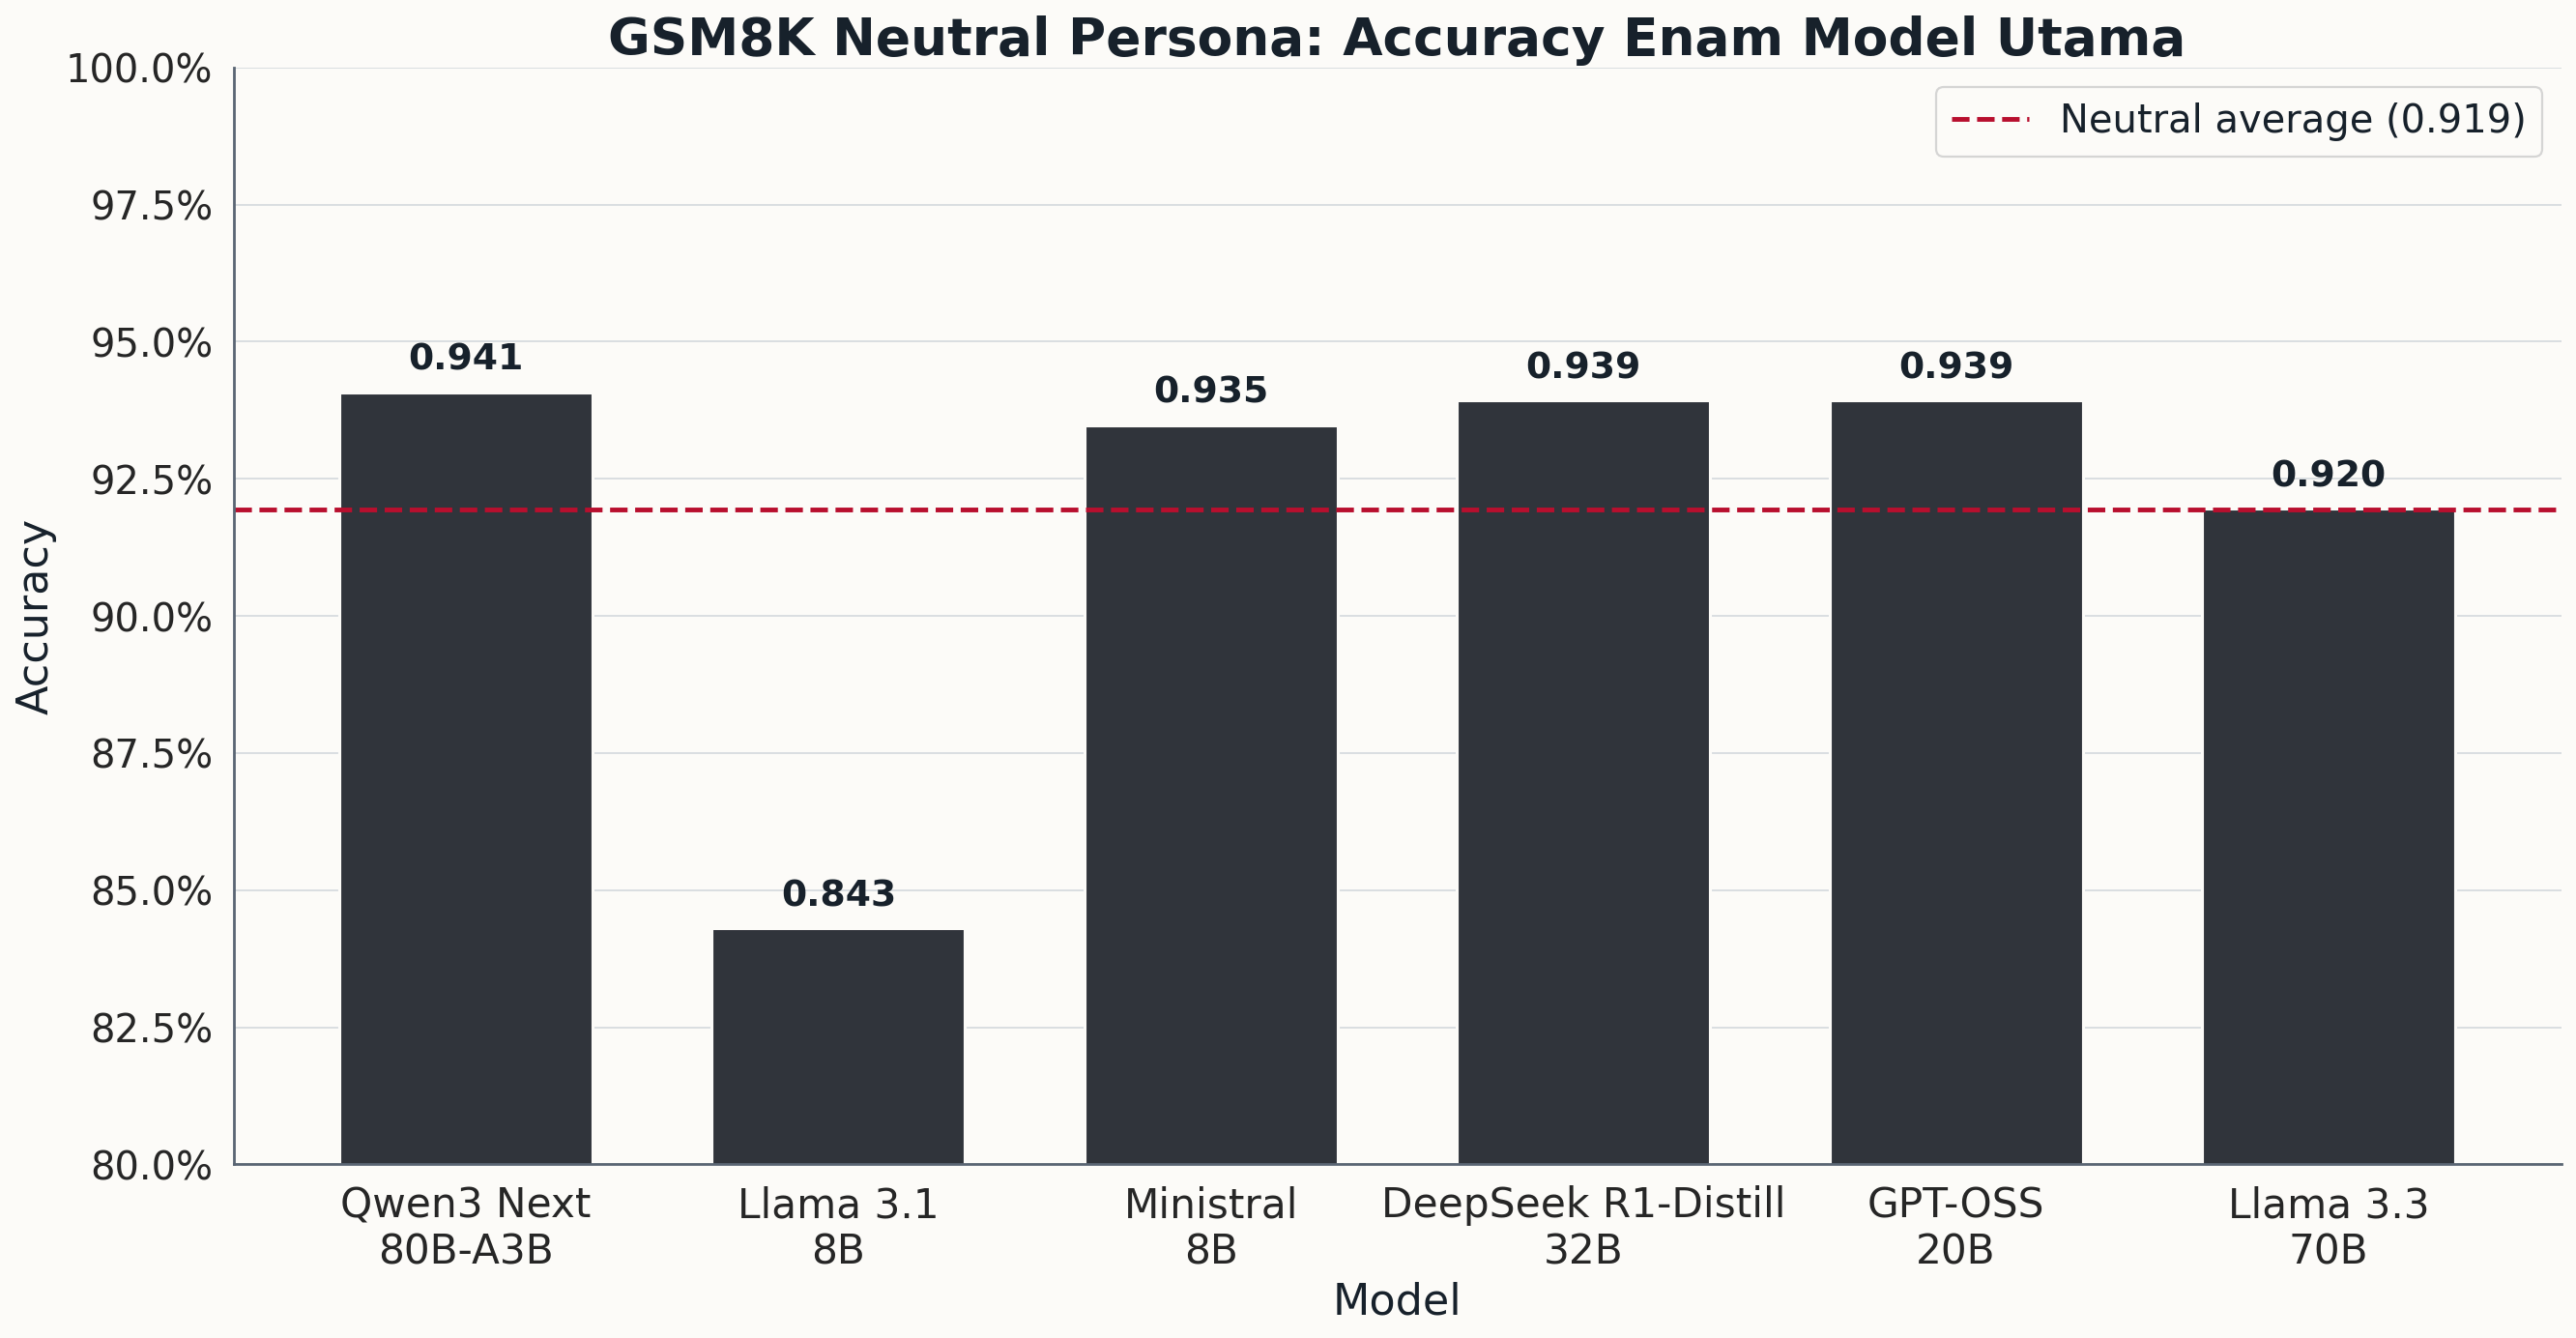

### Audit Qwen setelah rerun 4096

,persona,correct,total,total_ok,unresolved,coverage_pct,accuracy_all_responses_pct,accuracy_extracted_only_pct
0,neutral,1240,1318,1315,3,99.7724,94.0819,94.2966
1,man_explicit_1,1222,1319,1317,2,99.8484,92.6459,92.7866
2,man_implicit_1,1215,1319,1317,2,99.8484,92.1152,92.2551
3,man_implicit_2,1221,1319,1314,5,99.6209,92.5701,92.9224
4,man_implicit_3,1213,1319,1314,5,99.6209,91.9636,92.3135
5,woman_explicit_1,1236,1319,1317,2,99.8484,93.7074,93.8497
6,woman_implicit_1,1218,1319,1316,3,99.7726,92.3427,92.5532
7,woman_implicit_2,1221,1317,1313,4,99.6963,92.7107,92.9931
8,woman_implicit_3,1223,1319,1317,2,99.8484,92.7218,92.8626
9,OVERALL,11009,11868,11840,28,99.7641,92.7620,92.9814


### Marker signifikansi pada aggregate delta bars

,model,model_label,figure_scope,aggregate_bar,n_constituent_comparisons,n_significant_constituent_comparisons,minimum_holm_adjusted_p_value,significant_constituent_comparisons,star_marker,marker_interpretation
0,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,external_vs_neutral,Man Avg − Neutral,4,0,0.2745,NaN,NaN,At least one constituent two-sided Exact McNem...
1,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,external_vs_neutral,Woman Avg − Neutral,4,0,0.5303,NaN,NaN,At least one constituent two-sided Exact McNem...
2,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,external_vs_neutral,Man Avg − Woman Avg,4,0,0.3698,NaN,NaN,At least one constituent two-sided Exact McNem...
3,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,implicit_vs_explicit,Man Implicit Avg − Explicit,3,0,1.0000,NaN,NaN,At least one constituent two-sided Exact McNem...
4,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,implicit_vs_explicit,Woman Implicit Avg − Explicit,3,0,0.2897,NaN,NaN,At least one constituent two-sided Exact McNem...
5,qwen_qwen3-next-80b-a3b-thinking,Qwen3 Next 80B-A3B,implicit_vs_explicit,Man Avg − Woman Avg,4,0,0.3698,NaN,NaN,At least one constituent two-sided Exact McNem...
6,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,external_vs_neutral,Man Avg − Neutral,4,0,0.7925,NaN,NaN,At least one constituent two-sided Exact McNem...
7,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,external_vs_neutral,Woman Avg − Neutral,4,0,1.0000,NaN,NaN,At least one constituent two-sided Exact McNem...
8,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,external_vs_neutral,Man Avg − Woman Avg,4,0,1.0000,NaN,NaN,At least one constituent two-sided Exact McNem...
9,meta-llama_llama-3.1-8b-instruct,Llama 3.1 8B,implicit_vs_explicit,Man Implicit Avg − Explicit,3,0,0.7925,NaN,NaN,At least one constituent two-sided Exact McNem...


In [12]:
neutral_accuracy = pd.read_csv(TABLE_DIR / "neutral_persona_accuracy_six_models.csv")
qwen_rerun = pd.read_csv(TABLE_DIR / "qwen_gender_accuracy_after_rerun_4096.csv")
delta_markers = pd.read_csv(TABLE_DIR / "gender_delta_component_significance_markers.csv")

display(Markdown("### Neutral Persona"))
display(neutral_accuracy)
show_figure("23_neutral_persona_accuracy_six_models.png", width=1250)
display(Markdown("### Audit Qwen setelah rerun 4096"))
display(qwen_rerun)
display(Markdown("### Marker signifikansi pada aggregate delta bars"))
display(delta_markers)

## 9. Alternatif tata letak heatmap Holm

### `24_gender_effect_holm_single_portrait_heatmap.png`

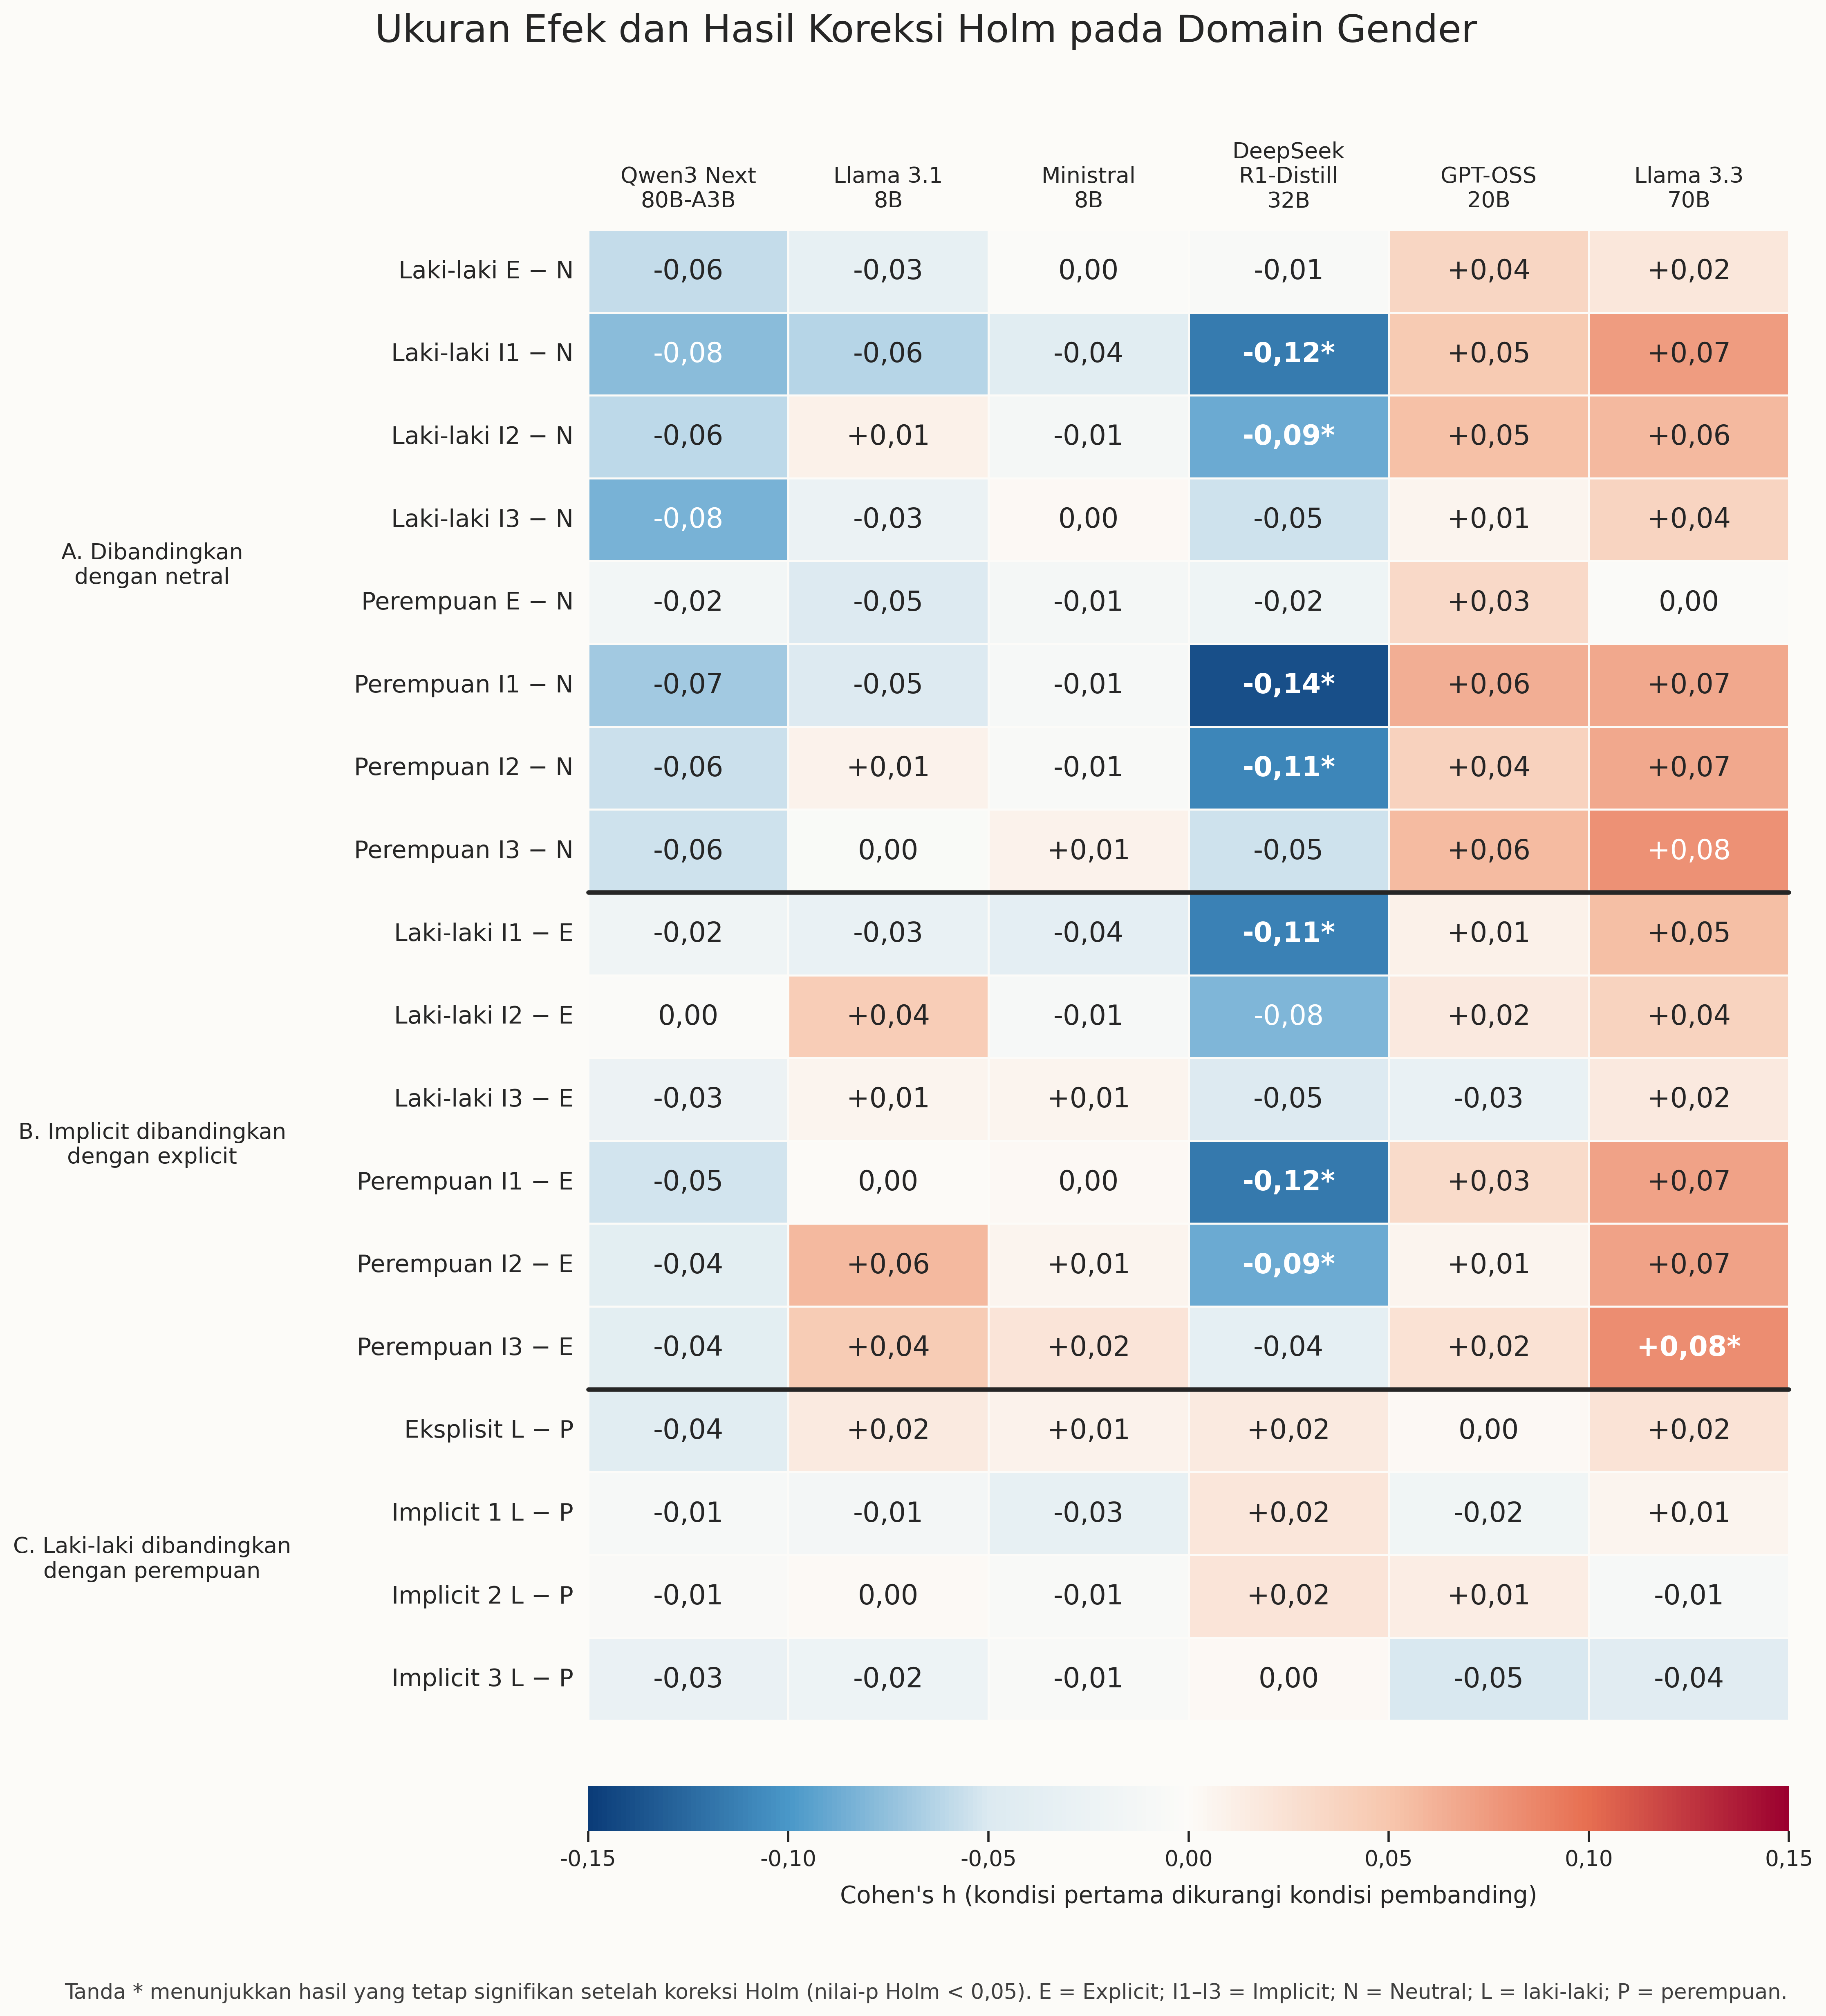

In [13]:
show_figure("24_gender_effect_holm_single_portrait_heatmap.png", width=1200)

## 10. CHECKLIST

In [14]:
gender_png = sorted({
    "01_gender_absolute_accuracy_five_categories.png",
    "02_gender_delta_vs_neutral.png",
    "03_gender_delta_implicit_vs_explicit.png",
    "04_gender_granular_effect_size_heatmap.png",
    "08_gender_completion_tokens_by_category.png",
    "09_gender_completion_token_delta_vs_neutral.png",
    "17_gender_exact_mcnemar_and_holm_pvalue_heatmap.png",
    "22_gender_completion_token_accuracy_tradeoff_implicit_vs_explicit.png",
    "23_neutral_persona_accuracy_six_models.png",
    "24_gender_effect_holm_single_large_heatmap.png",
    "24_gender_effect_holm_single_portrait_heatmap.png",
})
gender_svg = [name.replace(".png", ".svg") for name in gender_png]

for file_name in [*gender_png, *gender_svg]:
    path = FIGURE_DIR / file_name
    assert path.is_file() and path.stat().st_size > 0, path

checklist = pd.DataFrame(
    [
        ("[x]", "Full GSM8K test split; tidak ada sampling baru"),
        ("[x]", "6 model × 9 kondisi Gender tersedia"),
        ("[x]", "Coverage ditampilkan bersama accuracy"),
        ("[x]", "Cochran's Q, Exact McNemar, Cohen's h, dan Holm tersedia"),
        ("[x]", "Family Holm 7/7/4 tervalidasi"),
        ("[x]", "11 PNG dan 11 SVG Gender dapat dibuka"),
        ("[x]", "Hash seluruh visual bundle cocok dengan manifest"),
        ("[x]", "Tidak ada API call, parsing ulang, rescoring, atau uji ulang"),
    ],
    columns=["status", "item"],
)
display(checklist)

,status,item
0,[x],Full GSM8K test split; tidak ada sampling baru
1,[x],6 model × 9 kondisi Gender tersedia
2,[x],Coverage ditampilkan bersama accuracy
3,[x],"Cochran's Q, Exact McNemar, Cohen's h, dan Hol..."
4,[x],Family Holm 7/7/4 tervalidasi
5,[x],11 PNG dan 11 SVG Gender dapat dibuka
6,[x],Hash seluruh visual bundle cocok dengan manifest
7,[x],"Tidak ada API call, parsing ulang, rescoring, ..."


## 11. TESTING

In [15]:
output_index = pd.read_csv(FINAL_BUNDLE / "output_index.csv")
gender_output_index = output_index[
    output_index["file"].isin([*gender_png, *gender_svg])
    | output_index["file"].str.startswith("gender_", na=False)
    | output_index["file"].isin([
        "accuracy_by_persona_six_models.csv",
        "cochran_q_omnibus_all_groups.csv",
        "neutral_persona_accuracy_six_models.csv",
        "qwen_gender_accuracy_after_rerun_4096.csv",
    ])
].copy()
display(gender_output_index.reset_index(drop=True))

assert len(gender_png) == 11
assert len(gender_svg) == 11
assert gender_pairs["multiple_comparison_method"].eq("Holm").all()
assert gender_pairs["statistical_method"].eq("two-sided Exact McNemar").all()
assert not gender_accuracy.duplicated(["model", "persona"]).any()

print("TESTING LULUS: notebook, tabel, visual, dan kontrak statistik konsisten.")

,type,file,rows,columns,bytes
0,table,accuracy_by_persona_six_models.csv,246.0000,30.0000,81185
1,table,cochran_q_omnibus_all_groups.csv,84.0000,13.0000,15356
2,table,gender_completion_token_accuracy_spearman_expl...,7.0000,8.0000,1092
3,table,gender_completion_token_accuracy_tradeoff_impl...,36.0000,16.0000,8984
4,table,gender_completion_token_delta_vs_neutral_pct.csv,6.0000,5.0000,585
5,table,gender_delta_component_significance_markers.csv,36.0000,10.0000,9657
6,table,gender_five_category_and_deltas.csv,6.0000,15.0000,1822
7,table,gender_paired_effects_significance.csv,108.0000,38.0000,54857
8,table,neutral_persona_accuracy_six_models.csv,6.0000,9.0000,980
9,table,qwen_gender_accuracy_after_rerun_4096.csv,10.0000,8.0000,975


TESTING LULUS: notebook, tabel, visual, dan kontrak statistik konsisten.


## 12. INTEGRATION DAN BATAS INTERPRETASI

Notebook ini menjadi referensi tunggal untuk meniru tata letak GSM8K Gender pada
analisis persona lain. Statistik tetap berasal dari bundle v5; notebook ini tidak
menciptakan hasil inferensial baru.

Gunakan istilah **performance sensitivity to persona prompts**. Jangan langsung
menafsirkan perbedaan sebagai diskriminasi atau hubungan kausal. Rerata tiga kondisi
implicit hanya ringkasan visual; uji inferensial tetap memakai kondisi I1, I2, dan I3
secara terpisah. Keputusan utama dibaca dari `decision_significant_0_05`, bukan raw
p-value saja.

In [16]:
summary = {
    "repo_root": str(REPO_ROOT),
    "statistical_bundle": str(STAT_BUNDLE),
    "visual_bundle": str(FINAL_BUNDLE),
    "models": int(gender_accuracy["model"].nunique()),
    "personas": int(gender_accuracy["persona"].nunique()),
    "accuracy_rows": int(len(gender_accuracy)),
    "paired_comparisons": int(len(gender_pairs)),
    "holm_significant": int(gender_pairs["significant_holm_0_05"].sum()),
    "decision_significant": int(gender_pairs["decision_significant_0_05"].sum()),
    "gender_png_displayed": len(gender_png),
    "gender_svg_validated": len(gender_svg),
    "api_calls": 0,
    "rescoring": False,
}
display(pd.Series(summary, name="value").to_frame())
print("NOTEBOOK SELESAI DIJALANKAN TANPA ERROR")

,value
repo_root,D:\TugasAkhir
statistical_bundle,D:\TugasAkhir\result\GMS8K\reports\persona_pub...
visual_bundle,D:\TugasAkhir\result\GMS8K\reports\persona_pub...
models,6
personas,9
accuracy_rows,54
paired_comparisons,108
holm_significant,8
decision_significant,8
gender_png_displayed,11


NOTEBOOK SELESAI DIJALANKAN TANPA ERROR
